<a href="https://colab.research.google.com/github/putriikrima2/Dhaka-AQI-Forecasting/blob/main/Dhaka_AQI_Forecasting_Revised.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 1. Library

In [1]:
# Cell 1.1 - import library dan catat versi
import sys
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

print("Python :", sys.version.split()[0])
print("pandas :", pd.__version__)
print("numpy  :", np.__version__)


Python : 3.13.18
pandas : 2.2.3
numpy  : 2.4.6


In [2]:
# Cell 1.2 - upload dan baca dataset
from google.colab import files
uploaded = files.upload()

df = pd.read_csv("Dhaka_Climate_AQI_Data.csv")


Saving Dhaka_Climate_AQI_Data.csv to Dhaka_Climate_AQI_Data (1).csv


In [3]:
# Cell 1.3 - struktur awal
print(df.shape)
df.head()


(1096, 10)


,Date,District,Latitude,Longitude,Avg_Temperature_C,Rainfall_mm,Max_Wind_Speed_kmh,PM10,PM2.5,AQI_Level
0,2023-01-01,Dhaka,23.810332,90.412518,17.3,0.0,8.7,192.39,133.97,209.67
1,2023-01-02,Dhaka,23.810332,90.412518,17.6,0.0,9.3,142.08,98.30,179.71
2,2023-01-03,Dhaka,23.810332,90.412518,17.3,0.0,11.0,98.82,68.52,164.96
3,2023-01-04,Dhaka,23.810332,90.412518,17.3,0.0,12.2,74.28,51.72,151.12
4,2023-01-05,Dhaka,23.810332,90.412518,16.7,0.0,14.8,72.65,50.59,140.67


In [4]:

# Cell 1.4 - tipe data
df.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1096 entries, 0 to 1095
Data columns (total 10 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   Date                1096 non-null   object 
 1   District            1096 non-null   object 
 2   Latitude            1096 non-null   float64
 3   Longitude           1096 non-null   float64
 4   Avg_Temperature_C   1096 non-null   float64
 5   Rainfall_mm         1096 non-null   float64
 6   Max_Wind_Speed_kmh  1096 non-null   float64
 7   PM10                1096 non-null   float64
 8   PM2.5               1096 non-null   float64
 9   AQI_Level           1096 non-null   float64
dtypes: float64(8), object(2)
memory usage: 85.8+ KB


#2A. EDA bagian 1 :(struktur dan kualitas data)

In [5]:
# Cell 2A.1 - ukuran dan tipe data
print("Jumlah baris dan kolom:", df.shape)
print()
print(df.dtypes)


Jumlah baris dan kolom: (1096, 10)

Date                   object
District               object
Latitude              float64
Longitude             float64
Avg_Temperature_C     float64
Rainfall_mm           float64
Max_Wind_Speed_kmh    float64
PM10                  float64
PM2.5                 float64
AQI_Level             float64
dtype: object


In [6]:
# Cell 2A.2 - missing value dan duplikat
print("Missing value per kolom:")
print(df.isna().sum())
print()
print("Jumlah baris duplikat (semua kolom sama):", df.duplicated().sum())


Missing value per kolom:
Date                  0
District              0
Latitude              0
Longitude             0
Avg_Temperature_C     0
Rainfall_mm           0
Max_Wind_Speed_kmh    0
PM10                  0
PM2.5                 0
AQI_Level             0
dtype: int64

Jumlah baris duplikat (semua kolom sama): 0


In [7]:
# Cell 2A.3 - jumlah nilai unik per kolom
print("Jumlah nilai unik per kolom:")
print(df.nunique())


Jumlah nilai unik per kolom:
Date                  1096
District                 1
Latitude                 1
Longitude                1
Avg_Temperature_C      176
Rainfall_mm            220
Max_Wind_Speed_kmh     205
PM10                  1039
PM2.5                 1027
AQI_Level              937
dtype: int64


In [8]:
# Cell 2A.4 - statistik deskriptif
kolom_numerik = ["Avg_Temperature_C", "Rainfall_mm", "Max_Wind_Speed_kmh",
                 "PM10", "PM2.5", "AQI_Level"]
df[kolom_numerik].describe().round(2)


,Avg_Temperature_C,Rainfall_mm,Max_Wind_Speed_kmh,PM10,PM2.5,AQI_Level
count,1096.00,1096.00,1096.00,1096.00,1096.00,1096.00
mean,26.06,4.76,13.72,63.72,48.28,117.76
std,4.06,10.67,5.32,38.54,29.94,44.33
min,14.30,0.00,4.70,8.04,5.62,31.46
25%,23.20,0.00,9.70,32.68,24.86,78.34
50%,27.20,0.30,12.30,58.06,44.04,123.94
75%,29.10,5.20,16.73,87.48,66.85,157.01
max,33.80,174.70,55.50,270.69,188.69,241.08


In [9]:
# Cell 2A.5 - kemencengan (skewness)
print("Skewness:")
print(df[kolom_numerik].skew().round(2))


Skewness:
Avg_Temperature_C    -0.73
Rainfall_mm           6.14
Max_Wind_Speed_kmh    1.46
PM10                  0.97
PM2.5                 1.09
AQI_Level            -0.19
dtype: float64


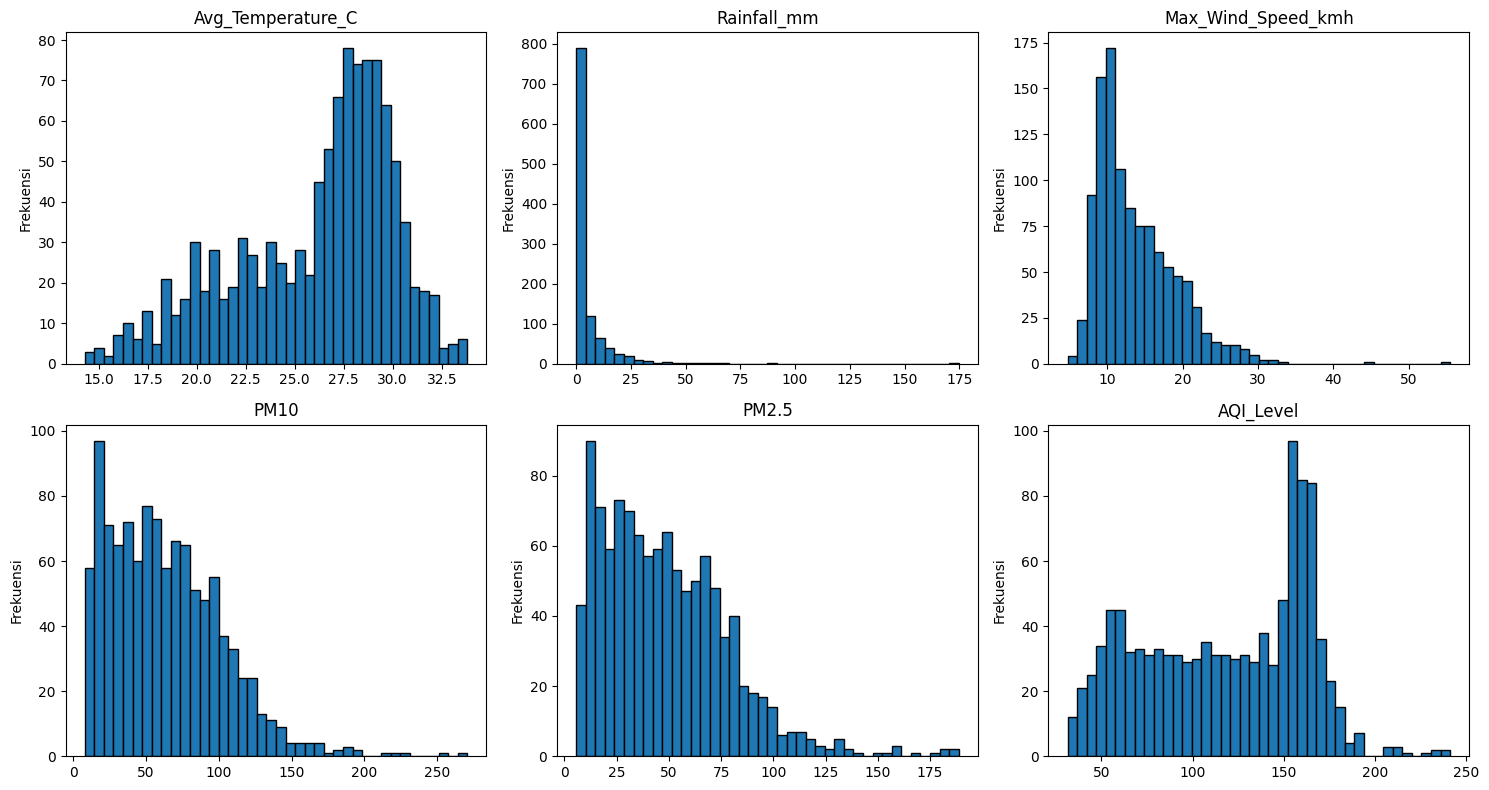

In [10]:
# Cell 2A.6 - histogram distribusi
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for ax, kol in zip(axes.ravel(), kolom_numerik):
    ax.hist(df[kol], bins=40, edgecolor="black")
    ax.set_title(kol)
    ax.set_ylabel("Frekuensi") #eng avg dilarangg _
plt.tight_layout()
plt.show()


# 3. Preprocessing Data


In [11]:
# Cell 3.1 - ubah tanggal ke datetime dan urutkan
df["Date"] = pd.to_datetime(df["Date"])
df = df.sort_values("Date").reset_index(drop=True)
print(df["Date"].dtype)


datetime64[ns]


In [12]:

# Cell 3.2 - validasi tanggal

print("Tanggal duplikat:", df["Date"].duplicated().sum())

print("Tanggal awal:", df["Date"].min())
print("Tanggal akhir:", df["Date"].max())

tanggal_lengkap = pd.date_range(
    start=df["Date"].min(),
    end=df["Date"].max(),
    freq="D"
)

tanggal_hilang = tanggal_lengkap.difference(df["Date"])

print("Jumlah tanggal seharusnya:", len(tanggal_lengkap))
print("Jumlah tanggal hilang:", len(tanggal_hilang))
print("Tanggal berurutan:", df["Date"].is_monotonic_increasing)

assert df["Date"].notna().all(), "Ada tanggal kosong"
assert not df["Date"].duplicated().any(), "Ada tanggal duplikat"
assert len(tanggal_hilang) == 0, "Ada tanggal yang hilang"

print("VALIDASI TANGGAL BERHASIL")


Tanggal duplikat: 0
Tanggal awal: 2023-01-01 00:00:00
Tanggal akhir: 2025-12-31 00:00:00
Jumlah tanggal seharusnya: 1096
Jumlah tanggal hilang: 0
Tanggal berurutan: True
VALIDASI TANGGAL BERHASIL


In [13]:

# Cell 3.3 - cek nilai tidak wajar
print("Nilai negatif per kolom:")
print((df[kolom_numerik] < 0).sum())
print()
print("Baris dengan PM2.5 > PM10:", (df["PM2.5"] > df["PM10"]).sum())
print()
print("Nilai min dan max:")
print(df[kolom_numerik].agg(["min", "max"]).T)
print()
print("5 hari dengan hujan tertinggi:")
print(df.nlargest(5, "Rainfall_mm")[["Date", "Rainfall_mm"]])


Nilai negatif per kolom:
Avg_Temperature_C     0
Rainfall_mm           0
Max_Wind_Speed_kmh    0
PM10                  0
PM2.5                 0
AQI_Level             0
dtype: int64

Baris dengan PM2.5 > PM10: 0

Nilai min dan max:
                      min     max
Avg_Temperature_C   14.30   33.80
Rainfall_mm          0.00  174.70
Max_Wind_Speed_kmh   4.70   55.50
PM10                 8.04  270.69
PM2.5                5.62  188.69
AQI_Level           31.46  241.08

5 hari dengan hujan tertinggi:
          Date  Rainfall_mm
512 2024-05-27        174.7
879 2025-05-29         88.9
641 2024-10-03         67.3
579 2024-08-02         66.4
643 2024-10-05         66.0


In [14]:
# Cell 3.4 - membentuk data kerja

data = (
    df[["Date"] + kolom_numerik]
    .set_index("Date")
    .sort_index()
    .asfreq("D")
)

print("Ukuran data:", data.shape)
print("Jumlah missing value:")
print(data.isna().sum())

assert data.index.is_unique, "Index tanggal tidak unik"
assert data.index.is_monotonic_increasing, "Tanggal belum berurutan"
assert not data.isna().any().any(), "Masih ada missing value"

print("DATA SIAP UNTUK FEATURE ENGINEERING")
display(data.head())


Ukuran data: (1096, 6)
Jumlah missing value:
Avg_Temperature_C     0
Rainfall_mm           0
Max_Wind_Speed_kmh    0
PM10                  0
PM2.5                 0
AQI_Level             0
dtype: int64
DATA SIAP UNTUK FEATURE ENGINEERING


,Avg_Temperature_C,Rainfall_mm,Max_Wind_Speed_kmh,PM10,PM2.5,AQI_Level
Date,,,,,,
2023-01-01,17.3,0.0,8.7,192.39,133.97,209.67
2023-01-02,17.6,0.0,9.3,142.08,98.30,179.71
2023-01-03,17.3,0.0,11.0,98.82,68.52,164.96
2023-01-04,17.3,0.0,12.2,74.28,51.72,151.12
2023-01-05,16.7,0.0,14.8,72.65,50.59,140.67


mengambil data yang siap untuk melatih model machine learning dan pembentukan fitur,mengubah kolom date menjadi indeks baris (1 januari 2023)

#2B. EDA bagian 2 (tren, musiman, dan korelasi)

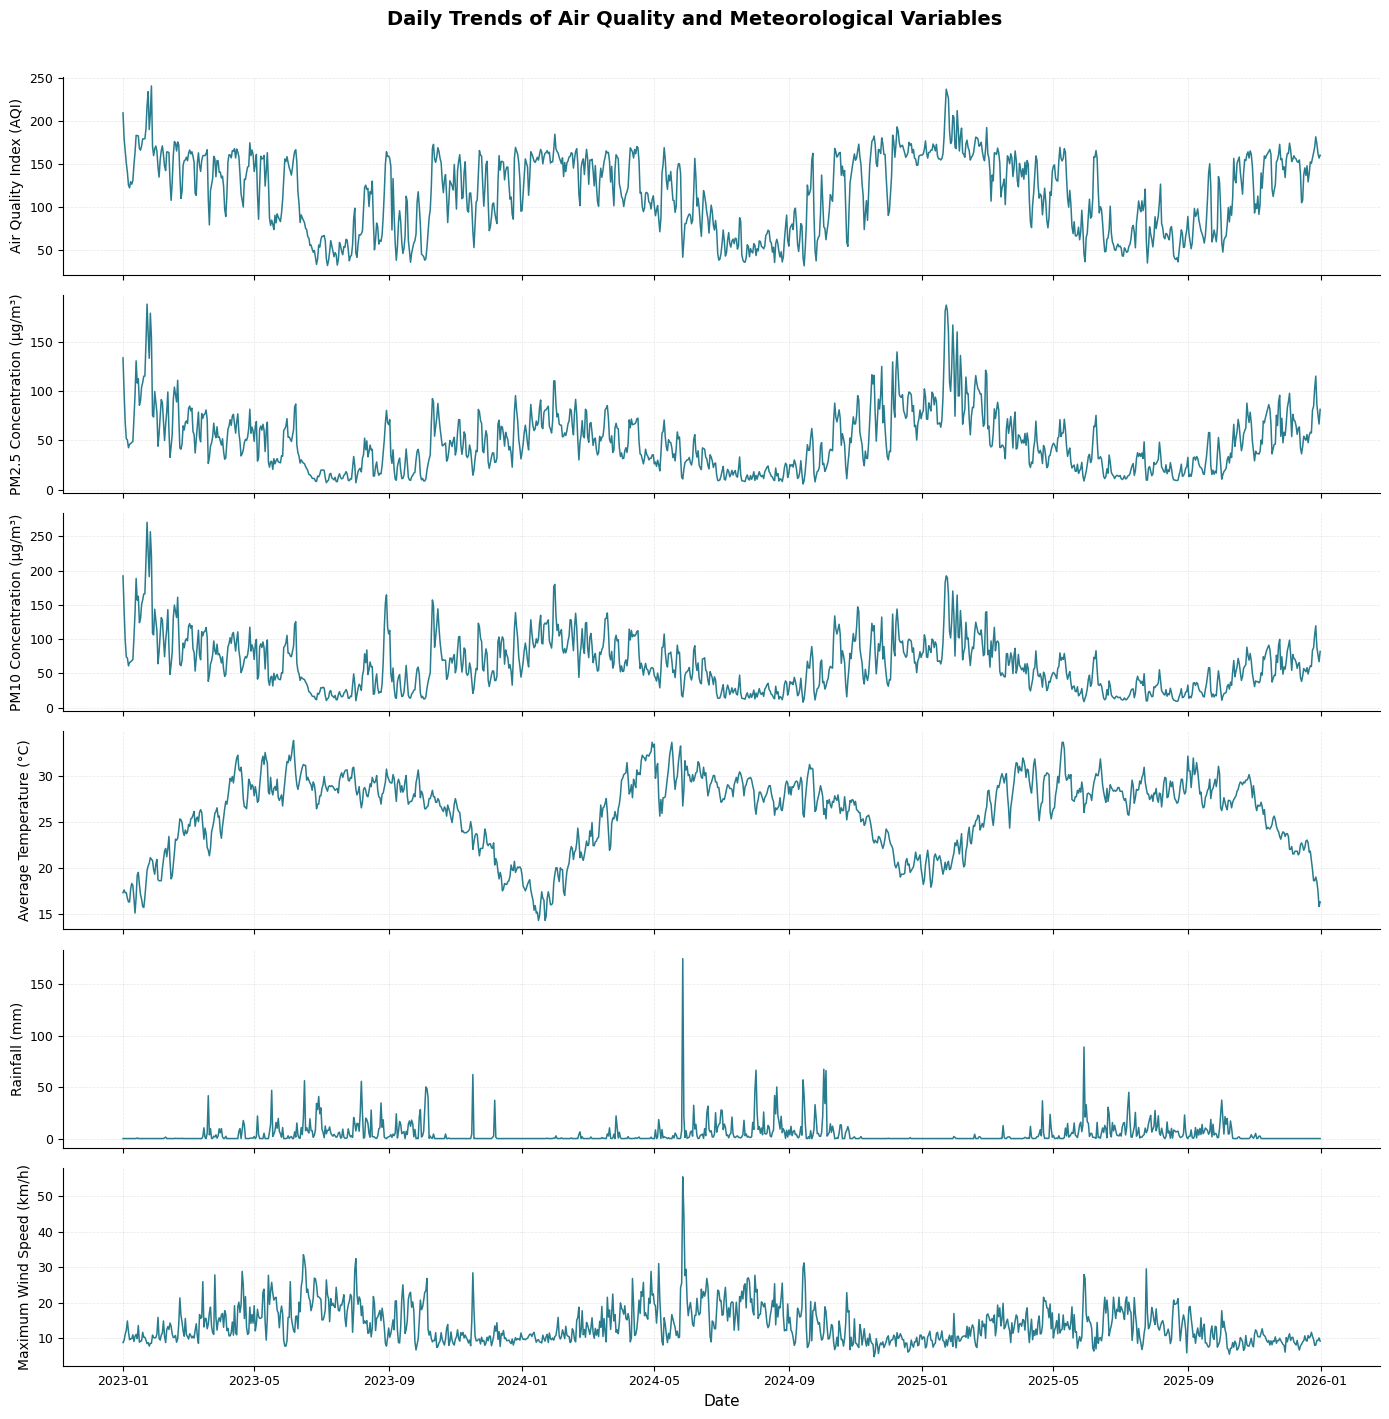

In [15]:

# Cell 2B.1 - Daily Trends of All Variables

variabel_plot = [
    ("AQI_Level", "Air Quality Index (AQI)"),
    ("PM2.5", "PM2.5 Concentration (µg/m³)"),
    ("PM10", "PM10 Concentration (µg/m³)"),
    ("Avg_Temperature_C", "Average Temperature (°C)"),
    ("Rainfall_mm", "Rainfall (mm)"),
    ("Max_Wind_Speed_kmh", "Maximum Wind Speed (km/h)")
]

fig, axes = plt.subplots(
    len(variabel_plot), 1,
    figsize=(14, 14),
    sharex=True
)

for ax, (kol, label) in zip(axes, variabel_plot):
    ax.plot(
        data.index,
        data[kol],
        color="#287C8E",
        linewidth=1.1
    )

    ax.set_ylabel(label, fontsize=10)
    ax.grid(True, linestyle="--", linewidth=0.5, alpha=0.3)

    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    ax.tick_params(axis="both", labelsize=9)

axes[-1].set_xlabel("Date", fontsize=11)

fig.suptitle(
    "Daily Trends of Air Quality and Meteorological Variables",
    fontsize=14,
    fontweight="bold",
    y=1.01
)

plt.tight_layout()
plt.show()


In [16]:
# Cell 2B.2 - rata-rata bulanan (semua tahun digabung)
rata_bulanan = data.groupby(data.index.month)[kolom_numerik].mean().round(2)
rata_bulanan.index.name = "bulan"
rata_bulanan


,Avg_Temperature_C,Rainfall_mm,Max_Wind_Speed_kmh,PM10,PM2.5,AQI_Level
bulan,,,,,,
1,18.40,0.05,9.94,117.30,90.62,167.30
2,22.02,0.32,11.74,102.13,76.98,158.29
3,25.92,1.98,14.20,83.12,58.95,144.27
4,29.44,2.13,16.09,67.52,47.35,130.15
5,29.36,7.92,16.42,55.32,39.35,112.71
6,29.43,9.00,17.76,42.41,29.88,89.59
7,28.78,7.57,18.05,21.99,16.74,58.66
8,28.11,11.29,16.21,33.12,22.81,72.03
9,28.85,7.71,13.96,35.13,26.45,82.40


In [17]:
# Cell 2B.3 - rata-rata AQI per bulan per tahun (apakah polanya konsisten?)
aqi_bulan_tahun = data.groupby([data.index.year, data.index.month])["AQI_Level"].mean().unstack(0).round(1)
aqi_bulan_tahun.index.name = "bulan"
aqi_bulan_tahun


Date,2023,2024,2025
bulan,,,
1,172.2,152.7,176.9
2,152.0,152.0,171.2
3,146.0,141.0,145.8
4,143.2,127.3,120.0
5,119.2,111.2,107.7
6,92.4,89.9,86.5
7,51.6,54.9,69.4
8,91.9,56.5,67.7
9,81.5,80.7,85.0


di EDA ini menemukan pola musiman berulang di tiap tahunnya, pola musimannya berada di awal tahun januari selalu tinggi dan dipertengahan tahun bulan juli selalu turun dan itu berulang di tiap tahunnya

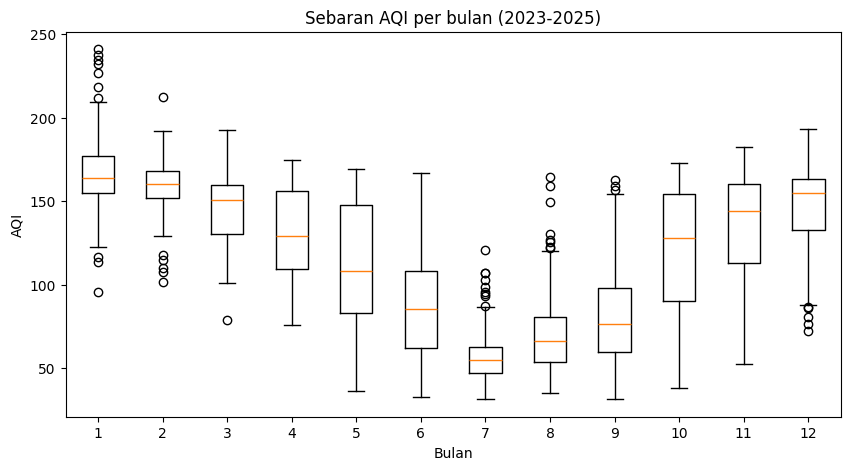

In [18]:
# Cell 2B.4 - boxplot AQI per bulan
plt.figure(figsize=(10, 5))
plt.boxplot([data.loc[data.index.month == m, "AQI_Level"] for m in range(1, 13)])
plt.xticks(range(1, 13), range(1, 13))
plt.xlabel("Bulan")
plt.ylabel("AQI")
plt.title("Sebaran AQI per bulan (2023-2025)")
plt.show()


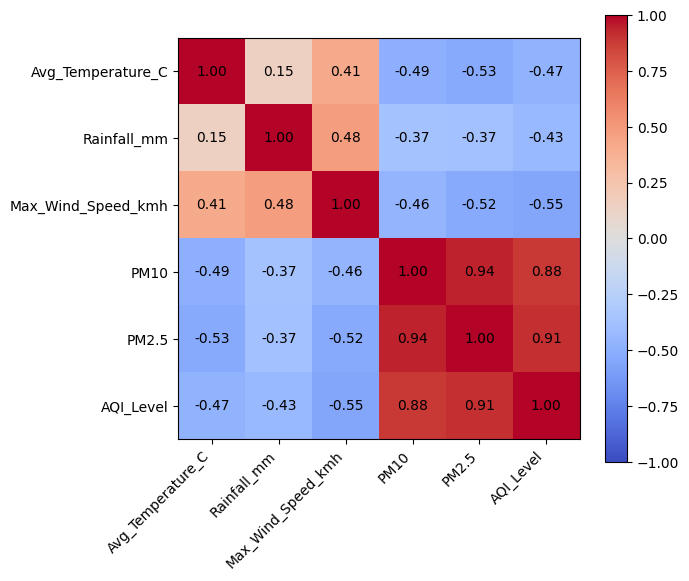

In [19]:
# Cell 2B.5 - korelasi antarvariabel (hari yang sama)
korelasi = data[kolom_numerik].corr()

fig, ax = plt.subplots(figsize=(7, 6))
im = ax.imshow(korelasi, cmap="coolwarm", vmin=-1, vmax=1)
ax.set_xticks(range(len(kolom_numerik)))
ax.set_xticklabels(kolom_numerik, rotation=45, ha="right")
ax.set_yticks(range(len(kolom_numerik)))
ax.set_yticklabels(kolom_numerik)
for i in range(len(kolom_numerik)):
    for j in range(len(kolom_numerik)):
        ax.text(j, i, f"{korelasi.iloc[i, j]:.2f}", ha="center", va="center")
plt.colorbar(im)
plt.tight_layout()
plt.show()


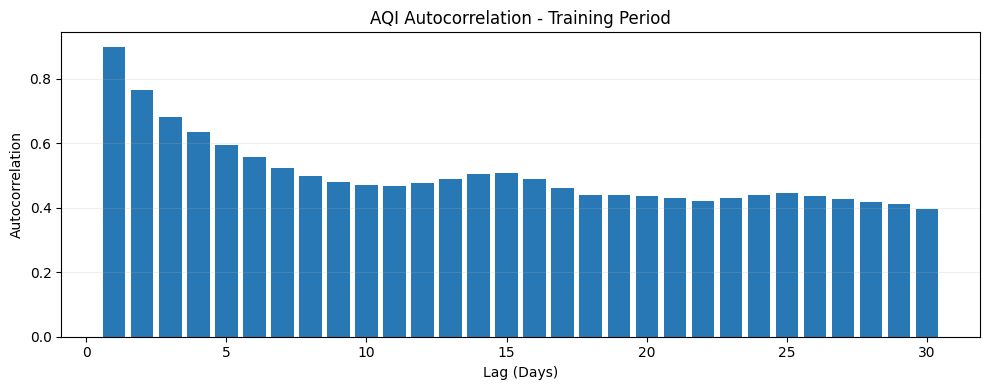

{1: np.float64(0.9), 2: np.float64(0.765), 3: np.float64(0.682), 4: np.float64(0.634), 5: np.float64(0.595), 6: np.float64(0.558), 10: np.float64(0.472)}


In [20]:
# Cell 2B.6 Autocorrelation Analysis Using Training Period

data_acf = data.loc[
    :"2024-06-30", "AQI_Level"
]

lags = range(1, 31)

acf = [
    data_acf.autocorr(lag=k)
    for k in lags
]

plt.figure(figsize=(10, 4))
plt.bar(lags, acf, color="#2878B5")

plt.xlabel("Lag (Days)")
plt.ylabel("Autocorrelation")
plt.title("AQI Autocorrelation - Training Period")
plt.grid(axis="y", alpha=0.2)

plt.tight_layout()
plt.show()

print({
    k: round(v, 3)
    for k, v in zip(lags, acf)
    if k in (1, 2, 3, 4, 5, 6, 10)
})

# eksprerimen pemilihan angka lag

In [21]:
# Cell L.1 - kandidat kombinasi lag

kandidat_lag = {
    "A": [0, 1, 2],
    "B": [0, 1, 2, 6],
    "C": [0, 1, 2, 3, 4, 5, 6],
    "D": [0, 1, 2, 10]
}

for nama, lag in kandidat_lag.items():
    print(f"Kandidat {nama}: {lag}")

print("\nJumlah baris data awal:", len(data))


Kandidat A: [0, 1, 2]
Kandidat B: [0, 1, 2, 6]
Kandidat C: [0, 1, 2, 3, 4, 5, 6]
Kandidat D: [0, 1, 2, 10]

Jumlah baris data awal: 1096


untuk kandidat a, digunakan untuk riwayat terdekat, kemudian B sama kayak sebelumnya, kalau C menggunakan seluruh riwayat 0-6, kemudian untuk D menguji riwayat yg lebih jauh

In [22]:
# Cell L.2 - membuat fitur lag untuk setiap kandidat

variabel_lag = ["AQI_Level", "PM2.5", "PM10"]

def buat_dataset_lag(data, daftar_lag):
    hasil = pd.DataFrame(index=data.index)

    for variabel in variabel_lag:
        for lag in daftar_lag:
            hasil[f"{variabel}_lag{lag}"] = data[variabel].shift(lag)

    # Target: AQI pada hari berikutnya
    hasil["target_AQI_besok"] = data["AQI_Level"].shift(-1)

    return hasil

dataset_kandidat = {}

for nama, daftar_lag in kandidat_lag.items():
    dataset_kandidat[nama] = buat_dataset_lag(
        data, daftar_lag
    )

    print(
        f"Kandidat {nama}: "
        f"{dataset_kandidat[nama].shape[1] - 1} fitur"
    )


Kandidat A: 9 fitur
Kandidat B: 12 fitur
Kandidat C: 21 fitur
Kandidat D: 12 fitur


In [23]:
# Cell L.3 - menyamakan tanggal observasi

tanggal_bersama = dataset_kandidat["D"].dropna().index

dataset_bersih = {}

for nama, dataset in dataset_kandidat.items():
    dataset_bersih[nama] = dataset.loc[
        tanggal_bersama
    ].copy()

    assert not dataset_bersih[nama].isna().any().any()

    print(
        f"Kandidat {nama}: "
        f"{len(dataset_bersih[nama])} baris"
    )

print("Tanggal awal:", tanggal_bersama.min())
print("Tanggal akhir:", tanggal_bersama.max())


Kandidat A: 1085 baris
Kandidat B: 1085 baris
Kandidat C: 1085 baris
Kandidat D: 1085 baris
Tanggal awal: 2023-01-11 00:00:00
Tanggal akhir: 2025-12-30 00:00:00


disamakan 1085 baris semua karena untuk mendapatkan perbandingn yang adil karna semuanya belajar dan diuji pada tgl yang sama

In [24]:
# Cell L.4 - pembagian berdasarkan tanggal target

tanggal_target = tanggal_bersama + pd.Timedelta(days=1)

mask_train = tanggal_target <= pd.Timestamp("2024-06-30")

mask_valid = (
    (tanggal_target >= pd.Timestamp("2024-07-01")) &
    (tanggal_target <= pd.Timestamp("2024-12-31"))
)

mask_test = tanggal_target >= pd.Timestamp("2025-01-01")

print("Training:", mask_train.sum())
print("Validation:", mask_valid.sum())
print("Test (disimpan):", mask_test.sum())

assert mask_train.sum() > 0
assert mask_valid.sum() > 0


Training: 536
Validation: 184
Test (disimpan): 365


In [25]:
# Cell L.5A - import model untuk eksperimen lag

from sklearn.ensemble import RandomForestRegressor
from xgboost import XGBRegressor
from lightgbm import LGBMRegressor

from sklearn.metrics import mean_absolute_error, mean_squared_error
import pandas as pd
import numpy as np


In [26]:
# Cell L.5B - konfigurasi model percobaan

model_percobaan = {
    "Random Forest": RandomForestRegressor(
        n_estimators=300,
        min_samples_leaf=2,
        random_state=42,
        n_jobs=-1
    ),

    "XGBoost": XGBRegressor(
        n_estimators=300,
        max_depth=3,
        learning_rate=0.05,
        objective="reg:squarederror",
        random_state=42,
        n_jobs=-1,
        verbosity=0
    ),

    "LightGBM": LGBMRegressor(
        n_estimators=300,
        max_depth=5,
        learning_rate=0.05,
        num_leaves=15,
        min_child_samples=20,
        random_state=42,
        n_jobs=-1,
        verbosity=-1
    )
}

print("Model siap digunakan:")
for nama in model_percobaan:
    print("-", nama)


Model siap digunakan:
- Random Forest
- XGBoost
- LightGBM


In [27]:
# Cell L.5C - eksperimen 4 kandidat lag x 3 model

from sklearn.base import clone

hasil_eksperimen_lag = []

for nama_kandidat, dataset in dataset_bersih.items():

    X = dataset.drop(columns=["target_AQI_besok"])
    y = dataset["target_AQI_besok"]

    X_train = X.loc[mask_train]
    y_train = y.loc[mask_train]

    X_valid = X.loc[mask_valid]
    y_valid = y.loc[mask_valid]

    for nama_model, model_dasar in model_percobaan.items():

        model = clone(model_dasar)

        # Model belajar dari data training
        model.fit(X_train, y_train)

        # Model memprediksi data validation
        y_pred = model.predict(X_valid)

        mae = mean_absolute_error(y_valid, y_pred)
        rmse = np.sqrt(
            mean_squared_error(y_valid, y_pred)
        )

        hasil_eksperimen_lag.append({
            "Kandidat": nama_kandidat,
            "Lag": str(kandidat_lag[nama_kandidat]),
            "Model": nama_model,
            "Jumlah_Fitur": X.shape[1],
            "MAE": mae,
            "RMSE": rmse
        })

        print(
            f"{nama_kandidat} | {nama_model} | "
            f"RMSE = {rmse:.4f}"
        )

hasil_eksperimen_lag = pd.DataFrame(
    hasil_eksperimen_lag
)

print("\nSEMUA EKSPERIMEN SELESAI")


A | Random Forest | RMSE = 10.7964
A | XGBoost | RMSE = 11.1658
A | LightGBM | RMSE = 10.4475
B | Random Forest | RMSE = 10.9642
B | XGBoost | RMSE = 11.1150
B | LightGBM | RMSE = 10.9123
C | Random Forest | RMSE = 11.0668
C | XGBoost | RMSE = 11.5782
C | LightGBM | RMSE = 11.1362
D | Random Forest | RMSE = 10.8369
D | XGBoost | RMSE = 11.2998
D | LightGBM | RMSE = 10.5280

SEMUA EKSPERIMEN SELESAI


In [28]:
# Cell L.5D - tabel RMSE tiap model dan kandidat

tabel_rmse_lag = hasil_eksperimen_lag.pivot(
    index="Kandidat",
    columns="Model",
    values="RMSE"
)

display(tabel_rmse_lag.round(4))


Model,LightGBM,Random Forest,XGBoost
Kandidat,,,
A,10.4475,10.7964,11.1658
B,10.9123,10.9642,11.1150
C,11.1362,11.0668,11.5782
D,10.5280,10.8369,11.2998


saya cuma mnggunakan RMSE sebagai metrik utama untuk pemilihan lag karena mau mendahulukan pengurangan kesalahan prediksi yang besar. MAE dan R² tetap dipakai evaluasi akhir untuk memberikan gambaran mengenai performa model

In [29]:
# Cell L.6 - menetapkan lag berdasarkan eksperimen awal

lag_list = [0, 1, 2]

print("Kombinasi lag terpilih:", lag_list)
print("Jumlah lag:", len(lag_list))
print("Alasan: RMSE terendah pada 2 dari 3 algoritma")


Kombinasi lag terpilih: [0, 1, 2]
Jumlah lag: 3
Alasan: RMSE terendah pada 2 dari 3 algoritma


jadi dari hasil percobaan eksperimen untuk memilih angka lag, dengan menggunakan 4 kombinasi lag, kemudian di uji menggunakan rf, xgboost, lgbm dari data training dan validasi, menunjukkan (0,1,2) mempunyai nilai RMSE yg paling rendah di RF dan LGBM.

# 4. Feature Engineering

In [30]:
# Cell 4.1 - membuat fitur lag utama

lag_list = [0, 1, 2]

peta_variabel = {
    "AQI": "AQI_Level",
    "PM25": "PM2.5",
    "PM10": "PM10",
    "Suhu": "Avg_Temperature_C",
    "Hujan": "Rainfall_mm",
    "Angin": "Max_Wind_Speed_kmh"
}

fe = pd.DataFrame(index=data.index)

for nama, kolom in peta_variabel.items():
    for k in lag_list:
        fe[f"{nama}_lag{k}"] = data[kolom].shift(k)

print("Ukuran fitur sebelum membuat target:", fe.shape)
display(fe.head(7))


Ukuran fitur sebelum membuat target: (1096, 18)


,AQI_lag0,AQI_lag1,AQI_lag2,PM25_lag0,PM25_lag1,PM25_lag2,PM10_lag0,PM10_lag1,PM10_lag2,Suhu_lag0,Suhu_lag1,Suhu_lag2,Hujan_lag0,Hujan_lag1,Hujan_lag2,Angin_lag0,Angin_lag1,Angin_lag2
Date,,,,,,,,,,,,,,,,,,
2023-01-01,209.67,NaN,NaN,133.97,NaN,NaN,192.39,NaN,NaN,17.3,NaN,NaN,0.0,NaN,NaN,8.7,NaN,NaN
2023-01-02,179.71,209.67,NaN,98.30,133.97,NaN,142.08,192.39,NaN,17.6,17.3,NaN,0.0,0.0,NaN,9.3,8.7,NaN
2023-01-03,164.96,179.71,209.67,68.52,98.30,133.97,98.82,142.08,192.39,17.3,17.6,17.3,0.0,0.0,0.0,11.0,9.3,8.7
2023-01-04,151.12,164.96,179.71,51.72,68.52,98.30,74.28,98.82,142.08,17.3,17.3,17.6,0.0,0.0,0.0,12.2,11.0,9.3
2023-01-05,140.67,151.12,164.96,50.59,51.72,68.52,72.65,74.28,98.82,16.7,17.3,17.3,0.0,0.0,0.0,14.8,12.2,11.0
2023-01-06,125.62,140.67,151.12,42.57,50.59,51.72,61.16,72.65,74.28,16.3,16.7,17.3,0.0,0.0,0.0,11.8,14.8,12.2
2023-01-07,122.33,125.62,140.67,46.03,42.57,50.59,65.95,61.16,72.65,16.3,16.3,16.7,0.0,0.0,0.0,9.5,11.8,14.8


ada bbrpa kolom masih Nan karna masih membutuhkan data desember 2022

In [31]:
# Cell 4.2 - membuat target prediksi hari berikutnya

fe["target_AQI_next"] = data["AQI_Level"].shift(-1)

print("Ukuran data setelah menambahkan target:", fe.shape)

display(
    fe[
        ["AQI_lag0", "AQI_lag1", "AQI_lag2",
         "target_AQI_next"]
    ].head(7)
)


Ukuran data setelah menambahkan target: (1096, 19)


,AQI_lag0,AQI_lag1,AQI_lag2,target_AQI_next
Date,,,,
2023-01-01,209.67,NaN,NaN,179.71
2023-01-02,179.71,209.67,NaN,164.96
2023-01-03,164.96,179.71,209.67,151.12
2023-01-04,151.12,164.96,179.71,140.67
2023-01-05,140.67,151.12,164.96,125.62
2023-01-06,125.62,140.67,151.12,122.33
2023-01-07,122.33,125.62,140.67,129.50


In [32]:
# Cell 4.3 - membandingkan AQI asli dan fitur lag

cek_feature = pd.DataFrame(index=data.index)

cek_feature["AQI_Asli"] = data["AQI_Level"]
cek_feature["AQI_lag0"] = fe["AQI_lag0"]
cek_feature["AQI_lag1"] = fe["AQI_lag1"]
cek_feature["AQI_lag2"] = fe["AQI_lag2"]
cek_feature["Target_AQI_Besok"] = fe["target_AQI_next"]

display(cek_feature.head(10))


,AQI_Asli,AQI_lag0,AQI_lag1,AQI_lag2,Target_AQI_Besok
Date,,,,,
2023-01-01,209.67,209.67,NaN,NaN,179.71
2023-01-02,179.71,179.71,209.67,NaN,164.96
2023-01-03,164.96,164.96,179.71,209.67,151.12
2023-01-04,151.12,151.12,164.96,179.71,140.67
2023-01-05,140.67,140.67,151.12,164.96,125.62
2023-01-06,125.62,125.62,140.67,151.12,122.33
2023-01-07,122.33,122.33,125.62,140.67,129.50
2023-01-08,129.50,129.50,122.33,125.62,126.58
2023-01-09,126.58,126.58,129.50,122.33,130.88


In [33]:
# Cell 4.4 - menyimpan fitur lag sebelum dropna

fe.to_csv(
    "Feature_Engineering_Sebelum_DropNA.csv",
    index=True,
    index_label="Date"
)

print("CSV sebelum DropNA berhasil dibuat.")


CSV sebelum DropNA berhasil dibuat.


In [34]:
# Cell 4.5 - membersihkan baris yang belum lengkap

print("Jumlah baris sebelum:", len(fe))
print("Jumlah nilai kosong sebelum:", fe.isna().sum().sum())

fe = fe.dropna().copy()

print("Jumlah baris sesudah:", len(fe))
print("Jumlah nilai kosong sesudah:", fe.isna().sum().sum())

assert len(fe) == 1093
assert not fe.isna().any().any()

display(fe.head())


Jumlah baris sebelum: 1096
Jumlah nilai kosong sebelum: 19
Jumlah baris sesudah: 1093
Jumlah nilai kosong sesudah: 0


,AQI_lag0,AQI_lag1,AQI_lag2,PM25_lag0,PM25_lag1,PM25_lag2,PM10_lag0,PM10_lag1,PM10_lag2,Suhu_lag0,Suhu_lag1,Suhu_lag2,Hujan_lag0,Hujan_lag1,Hujan_lag2,Angin_lag0,Angin_lag1,Angin_lag2,target_AQI_next
Date,,,,,,,,,,,,,,,,,,,
2023-01-03,164.96,179.71,209.67,68.52,98.30,133.97,98.82,142.08,192.39,17.3,17.6,17.3,0.0,0.0,0.0,11.0,9.3,8.7,151.12
2023-01-04,151.12,164.96,179.71,51.72,68.52,98.30,74.28,98.82,142.08,17.3,17.3,17.6,0.0,0.0,0.0,12.2,11.0,9.3,140.67
2023-01-05,140.67,151.12,164.96,50.59,51.72,68.52,72.65,74.28,98.82,16.7,17.3,17.3,0.0,0.0,0.0,14.8,12.2,11.0,125.62
2023-01-06,125.62,140.67,151.12,42.57,50.59,51.72,61.16,72.65,74.28,16.3,16.7,17.3,0.0,0.0,0.0,11.8,14.8,12.2,122.33
2023-01-07,122.33,125.62,140.67,46.03,42.57,50.59,65.95,61.16,72.65,16.3,16.3,16.7,0.0,0.0,0.0,9.5,11.8,14.8,129.50


setelah dropna ini baris tgl 1,2 januari tidak ikut masuk untuk baris sampel, tetapi datanya ttp kepakai untuk lag 1,2 karna lag0 makai data pda hari itu

In [35]:
# Cell 4.6 - menyimpan dataset siap pemodelan

fe.to_csv(
    "Feature_Engineering_Siap_Model.csv",
    index=True,
    index_label="Date"
)

print("CSV dataset siap model berhasil dibuat.")
print("Jumlah baris:", len(fe))
print("Jumlah kolom:", fe.shape[1])


CSV dataset siap model berhasil dibuat.
Jumlah baris: 1093
Jumlah kolom: 19


# 5. menentukan fitur S1 dan S2

In [36]:
# Cell 5.1 - menentukan fitur S1 dan S2

# Fitur polutan dan AQI
fitur_aqi = [f"AQI_lag{k}" for k in lag_list]
fitur_pm25 = [f"PM25_lag{k}" for k in lag_list]
fitur_pm10 = [f"PM10_lag{k}" for k in lag_list]

# Fitur meteorologi
fitur_suhu = [f"Suhu_lag{k}" for k in lag_list]
fitur_hujan = [f"Hujan_lag{k}" for k in lag_list]
fitur_angin = [f"Angin_lag{k}" for k in lag_list]

# Skenario 1: tanpa meteorologi
fitur_s1 = fitur_aqi + fitur_pm25 + fitur_pm10

# Skenario 2: dengan meteorologi
fitur_met = fitur_suhu + fitur_hujan + fitur_angin
fitur_s2 = fitur_s1 + fitur_met

print("Jumlah fitur S1:", len(fitur_s1))
print("Jumlah fitur S2:", len(fitur_s2))

print("\nFitur S1:")
print(fitur_s1)

print("\nFitur S2:")
print(fitur_s2)


Jumlah fitur S1: 9
Jumlah fitur S2: 18

Fitur S1:
['AQI_lag0', 'AQI_lag1', 'AQI_lag2', 'PM25_lag0', 'PM25_lag1', 'PM25_lag2', 'PM10_lag0', 'PM10_lag1', 'PM10_lag2']

Fitur S2:
['AQI_lag0', 'AQI_lag1', 'AQI_lag2', 'PM25_lag0', 'PM25_lag1', 'PM25_lag2', 'PM10_lag0', 'PM10_lag1', 'PM10_lag2', 'Suhu_lag0', 'Suhu_lag1', 'Suhu_lag2', 'Hujan_lag0', 'Hujan_lag1', 'Hujan_lag2', 'Angin_lag0', 'Angin_lag1', 'Angin_lag2']


In [37]:
# Cell 5.2 - menyiapkan input dan target (x dan y)

target = "target_AQI_next"

X_s1 = fe[fitur_s1].copy()
X_s2 = fe[fitur_s2].copy()
y = fe[target].copy()

print("Ukuran X_s1:", X_s1.shape)
print("Ukuran X_s2:", X_s2.shape)
print("Ukuran y:", y.shape)

assert X_s1.index.equals(X_s2.index)
assert X_s1.index.equals(y.index)

assert not X_s1.isna().any().any()
assert not X_s2.isna().any().any()
assert not y.isna().any()

print("\nSemua data sudah sesuai.")


Ukuran X_s1: (1093, 9)
Ukuran X_s2: (1093, 18)
Ukuran y: (1093,)

Semua data sudah sesuai.


In [38]:
# Cell 5.3 - melihat fitur skenario 1

print("SKENARIO 1 - TANPA METEOROLOGI")

display(X_s1.head(5))


SKENARIO 1 - TANPA METEOROLOGI


,AQI_lag0,AQI_lag1,AQI_lag2,PM25_lag0,PM25_lag1,PM25_lag2,PM10_lag0,PM10_lag1,PM10_lag2
Date,,,,,,,,,
2023-01-03,164.96,179.71,209.67,68.52,98.30,133.97,98.82,142.08,192.39
2023-01-04,151.12,164.96,179.71,51.72,68.52,98.30,74.28,98.82,142.08
2023-01-05,140.67,151.12,164.96,50.59,51.72,68.52,72.65,74.28,98.82
2023-01-06,125.62,140.67,151.12,42.57,50.59,51.72,61.16,72.65,74.28
2023-01-07,122.33,125.62,140.67,46.03,42.57,50.59,65.95,61.16,72.65


In [39]:
# Cell 5.4 - melihat fitur skenario 2

print("SKENARIO 2 - DENGAN METEOROLOGI")

display(X_s2.head(5))


SKENARIO 2 - DENGAN METEOROLOGI


,AQI_lag0,AQI_lag1,AQI_lag2,PM25_lag0,PM25_lag1,PM25_lag2,PM10_lag0,PM10_lag1,PM10_lag2,Suhu_lag0,Suhu_lag1,Suhu_lag2,Hujan_lag0,Hujan_lag1,Hujan_lag2,Angin_lag0,Angin_lag1,Angin_lag2
Date,,,,,,,,,,,,,,,,,,
2023-01-03,164.96,179.71,209.67,68.52,98.30,133.97,98.82,142.08,192.39,17.3,17.6,17.3,0.0,0.0,0.0,11.0,9.3,8.7
2023-01-04,151.12,164.96,179.71,51.72,68.52,98.30,74.28,98.82,142.08,17.3,17.3,17.6,0.0,0.0,0.0,12.2,11.0,9.3
2023-01-05,140.67,151.12,164.96,50.59,51.72,68.52,72.65,74.28,98.82,16.7,17.3,17.3,0.0,0.0,0.0,14.8,12.2,11.0
2023-01-06,125.62,140.67,151.12,42.57,50.59,51.72,61.16,72.65,74.28,16.3,16.7,17.3,0.0,0.0,0.0,11.8,14.8,12.2
2023-01-07,122.33,125.62,140.67,46.03,42.57,50.59,65.95,61.16,72.65,16.3,16.3,16.7,0.0,0.0,0.0,9.5,11.8,14.8


In [40]:
# Cell 5.5 - memastikan kedua skenario memakai target sama

print("Contoh target AQI besok:")

display(
    pd.DataFrame({
        "AQI_hari_ini": fe["AQI_lag0"],
        "Target_AQI_besok": y
    }).head(10)
)

assert len(X_s1) == len(X_s2) == len(y)

print("\nS1 dan S2 menggunakan tanggal serta target yang sama.")


Contoh target AQI besok:


,AQI_hari_ini,Target_AQI_besok
Date,,
2023-01-03,164.96,151.12
2023-01-04,151.12,140.67
2023-01-05,140.67,125.62
2023-01-06,125.62,122.33
2023-01-07,122.33,129.50
2023-01-08,129.50,126.58
2023-01-09,126.58,130.88
2023-01-10,130.88,149.00
2023-01-11,149.00,163.58



S1 dan S2 menggunakan tanggal serta target yang sama.


# 6. Pembagian data training, validation dan testing

In [41]:
# Cell 6.1 - menentukan tanggal target AQI besok

tanggal_input = fe.index

tanggal_target = tanggal_input + pd.Timedelta(days=1)

cek_tanggal = pd.DataFrame({
    "Tanggal_Input": tanggal_input,
    "Tanggal_Target": tanggal_target,
    "AQI_Hari_Ini": fe["AQI_lag0"].values,
    "Target_AQI_Besok": y.values
})

display(cek_tanggal.head(5))

print("Tanggal target pertama:", tanggal_target.min())
print("Tanggal target terakhir:", tanggal_target.max())



,Tanggal_Input,Tanggal_Target,AQI_Hari_Ini,Target_AQI_Besok
0,2023-01-03,2023-01-04,164.96,151.12
1,2023-01-04,2023-01-05,151.12,140.67
2,2023-01-05,2023-01-06,140.67,125.62
3,2023-01-06,2023-01-07,125.62,122.33
4,2023-01-07,2023-01-08,122.33,129.50


Tanggal target pertama: 2023-01-04 00:00:00
Tanggal target terakhir: 2025-12-31 00:00:00


In [42]:
# Cell 6.2 - membuat pembagian temporal

idx_train = tanggal_target <= pd.Timestamp("2024-06-30")

idx_val = (
    (tanggal_target >= pd.Timestamp("2024-07-01")) &
    (tanggal_target <= pd.Timestamp("2024-12-31"))
)

idx_test = (
    (tanggal_target >= pd.Timestamp("2025-01-01")) &
    (tanggal_target <= pd.Timestamp("2025-12-31"))
)

print("Jumlah training:", idx_train.sum())
print("Jumlah validation:", idx_val.sum())
print("Jumlah testing:", idx_test.sum())

assert (idx_train.sum() + idx_val.sum() + idx_test.sum()) == len(fe)
assert not np.any(idx_train & idx_val)
assert not np.any(idx_train & idx_test)
assert not np.any(idx_val & idx_test)

print("\nPembagian data berhasil!")


Jumlah training: 544
Jumlah validation: 184
Jumlah testing: 365

Pembagian data berhasil!


menggunakan data setelah dilakukan feature engineering dengn 1093 baris

In [43]:
# Cell 6.3 - split untuk skenario S1

X_train_s1 = X_s1.loc[idx_train].copy()
X_val_s1 = X_s1.loc[idx_val].copy()
X_test_s1 = X_s1.loc[idx_test].copy()

y_train = y.loc[idx_train].copy()
y_val = y.loc[idx_val].copy()
y_test = y.loc[idx_test].copy()

print("TRAIN S1:", X_train_s1.shape)
print("VALIDATION S1:", X_val_s1.shape)
print("TEST S1:", X_test_s1.shape)


TRAIN S1: (544, 9)
VALIDATION S1: (184, 9)
TEST S1: (365, 9)


In [44]:
# Cell 6.4 - split untuk skenario S2

X_train_s2 = X_s2.loc[idx_train].copy()
X_val_s2 = X_s2.loc[idx_val].copy()
X_test_s2 = X_s2.loc[idx_test].copy()

print("TRAIN S2:", X_train_s2.shape)
print("VALIDATION S2:", X_val_s2.shape)
print("TEST S2:", X_test_s2.shape)


TRAIN S2: (544, 18)
VALIDATION S2: (184, 18)
TEST S2: (365, 18)


In [45]:
# Cell 6.5 - pemeriksaan akhir temporal split

assert len(X_train_s1) == len(X_train_s2) == len(y_train)
assert len(X_val_s1) == len(X_val_s2) == len(y_val)
assert len(X_test_s1) == len(X_test_s2) == len(y_test)

assert len(y_train) == 544
assert len(y_val) == 184
assert len(y_test) == 365

print("HASIL PEMBAGIAN FINAL")
print("-" * 35)
print(f"Training   : {len(y_train)} data")
print(f"Validation : {len(y_val)} data")
print(f"Testing    : {len(y_test)} data")
print(f"Total      : {len(fe)} data")

print("\nSemua pemeriksaan berhasil!")


HASIL PEMBAGIAN FINAL
-----------------------------------
Training   : 544 data
Validation : 184 data
Testing    : 365 data
Total      : 1093 data

Semua pemeriksaan berhasil!


# 7. Hyparameter Tuning

In [46]:
# Cell 7.1 - import library untuk training

from sklearn.ensemble import RandomForestRegressor
from xgboost import XGBRegressor
from lightgbm import LGBMRegressor

from sklearn.metrics import mean_absolute_error, mean_squared_error
from sklearn.base import clone
from itertools import product

import pandas as pd
import numpy as np
import time

print("Semua library berhasil diimport!")


Semua library berhasil diimport!


In [47]:
# Cell 7.2 - hyperparameter grid berbasis literatur

parameter_grid = {
    "Random Forest": {
        "n_estimators": [150, 300],
        "max_depth": [10, 15],
        "min_samples_leaf": [2, 4]
    },

    "XGBoost": {
        "n_estimators": [100, 300, 500],
        "max_depth": [3, 5],
        "learning_rate": [0.01, 0.05, 0.1]
    },

    "LightGBM": {
        "n_estimators": [100, 300, 500],
        "num_leaves": [15, 31],
        "learning_rate": [0.01, 0.05, 0.1]
    }
}

total = 0

for nama, grid in parameter_grid.items():
    jumlah = int(np.prod([len(v) for v in grid.values()]))
    total += jumlah
    print(f"{nama}: {jumlah} kombinasi")

print(f"\nTotal per skenario: {total}")
print(f"Total S1 + S2: {total * 2}")


Random Forest: 8 kombinasi
XGBoost: 18 kombinasi
LightGBM: 18 kombinasi

Total per skenario: 44
Total S1 + S2: 88


In [48]:
# Cell 7.3 - fungsi untuk membuat model

from sklearn.ensemble import RandomForestRegressor
from xgboost import XGBRegressor
from lightgbm import LGBMRegressor

def buat_model(nama_model, params):

    if nama_model == "Random Forest":
        return RandomForestRegressor(
            **params,
            random_state=42,
            n_jobs=-1
        )

    elif nama_model == "XGBoost":
        return XGBRegressor(
            **params,
            objective="reg:squarederror",
            random_state=42,
            n_jobs=-1,
            verbosity=0
        )

    elif nama_model == "LightGBM":
        return LGBMRegressor(
            **params,
            max_depth=-1,
            min_child_samples=10,
            random_state=42,
            n_jobs=-1,
            verbosity=-1
        )

    else:
        raise ValueError("Model tidak dikenali")

print("Fungsi ketiga model berhasil dibuat!")


Fungsi ketiga model berhasil dibuat!


In [49]:
# Cell 7.4 - fungsi untuk mencoba kombinasi hyperparameter

from itertools import product
from sklearn.metrics import mean_squared_error, mean_absolute_error
import numpy as np
import pandas as pd

def tuning_model(nama_model, X_train, X_val, y_train, y_val):

    grid = parameter_grid[nama_model]

    nama_parameter = list(grid.keys())
    kombinasi = list(product(*grid.values()))

    hasil = []

    for nomor, nilai in enumerate(kombinasi, start=1):

        params = dict(zip(nama_parameter, nilai))

        model = buat_model(nama_model, params)

        model.fit(X_train, y_train)

        prediksi = model.predict(X_val)

        rmse = np.sqrt(
            mean_squared_error(y_val, prediksi)
        )

        mae = mean_absolute_error(y_val, prediksi)

        hasil.append({
            "Model": nama_model,
            "Kombinasi": nomor,
            "Parameters": params.copy(),
            "RMSE_Validation": rmse,
            "MAE_Validation": mae
        })

    tabel = pd.DataFrame(hasil)

    tabel = tabel.sort_values(
        by=["RMSE_Validation", "MAE_Validation"]
    ).reset_index(drop=True)

    return tabel

print("Fungsi hyperparameter tuning siap!")


Fungsi hyperparameter tuning siap!


In [50]:
# Cell 7.5 - menyiapkan kedua skenario

skenario_data = {
    "S1": {
        "X_train": X_train_s1,
        "X_val": X_val_s1
    },

    "S2": {
        "X_train": X_train_s2,
        "X_val": X_val_s2
    }
}

print("Skenario yang akan diuji:")
print("S1: tanpa meteorologi")
print("S2: dengan meteorologi")


Skenario yang akan diuji:
S1: tanpa meteorologi
S2: dengan meteorologi


In [51]:
# Cell 7.6 - menjalankan tuning semua model

import time

hasil_tuning_semua = {}
ringkasan_tuning = []

mulai = time.time()

for skenario, dataset in skenario_data.items():

    for nama_model in parameter_grid.keys():

        print(f"\nTuning {nama_model} - {skenario} ...")

        tabel_hasil = tuning_model(
            nama_model,
            dataset["X_train"],
            dataset["X_val"],
            y_train,
            y_val
        )

        hasil_tuning_semua[(nama_model, skenario)] = tabel_hasil

        terbaik = tabel_hasil.iloc[0]

        ringkasan_tuning.append({
            "Model": nama_model,
            "Skenario": skenario,
            "RMSE_Validation": terbaik["RMSE_Validation"],
            "MAE_Validation": terbaik["MAE_Validation"],
            "Best_Parameters": terbaik["Parameters"]
        })

        print(
            f"RMSE validation terbaik: "
            f"{terbaik['RMSE_Validation']:.4f}"
        )

print(
    f"\nTotal waktu tuning: "
    f"{time.time() - mulai:.2f} detik"
)



Tuning Random Forest - S1 ...
RMSE validation terbaik: 10.5744

Tuning XGBoost - S1 ...
RMSE validation terbaik: 10.5880

Tuning LightGBM - S1 ...
RMSE validation terbaik: 11.2995

Tuning Random Forest - S2 ...
RMSE validation terbaik: 10.6610

Tuning XGBoost - S2 ...
RMSE validation terbaik: 11.0404

Tuning LightGBM - S2 ...
RMSE validation terbaik: 11.3273

Total waktu tuning: 43.65 detik


In [52]:
# Cell 7.7 - menampilkan hasil tuning terbaik

df_ringkasan_tuning = pd.DataFrame(ringkasan_tuning)

df_ringkasan_tuning = df_ringkasan_tuning.sort_values(
    by=["Model", "Skenario"]
).reset_index(drop=True)

display(df_ringkasan_tuning)


,Model,Skenario,RMSE_Validation,MAE_Validation,Best_Parameters
0,LightGBM,S1,11.299481,8.702831,"{'n_estimators': 100, 'num_leaves': 15, 'learn..."
1,LightGBM,S2,11.327270,8.720075,"{'n_estimators': 500, 'num_leaves': 15, 'learn..."
2,Random Forest,S1,10.574381,8.118375,"{'n_estimators': 150, 'max_depth': 10, 'min_sa..."
3,Random Forest,S2,10.660957,8.227607,"{'n_estimators': 150, 'max_depth': 15, 'min_sa..."
4,XGBoost,S1,10.588029,8.204866,"{'n_estimators': 500, 'max_depth': 3, 'learnin..."
5,XGBoost,S2,11.040436,8.626489,"{'n_estimators': 100, 'max_depth': 3, 'learnin..."


In [53]:
# Cell 7.8 - perbandingan RMSE validation

tabel_perbandingan = df_ringkasan_tuning.pivot(
    index="Model",
    columns="Skenario",
    values="RMSE_Validation"
)

tabel_perbandingan["Selisih_S2_minus_S1"] = (
    tabel_perbandingan["S2"] -
    tabel_perbandingan["S1"]
)

display(tabel_perbandingan.round(4))


Skenario,S1,S2,Selisih_S2_minus_S1
Model,,,
LightGBM,11.2995,11.3273,0.0278
Random Forest,10.5744,10.6610,0.0866
XGBoost,10.5880,11.0404,0.4524


In [54]:
# Cell 7.9 - menyimpan hasil tuning

semua_kombinasi = []

for (nama_model, skenario), tabel in hasil_tuning_semua.items():

    temp = tabel.copy()
    temp["Skenario"] = skenario

    semua_kombinasi.append(temp)

df_semua_tuning = pd.concat(
    semua_kombinasi,
    ignore_index=True
)

df_semua_tuning.to_csv(
    "Hasil_Seluruh_Hyperparameter_Tuning.csv",
    index=False
)

df_ringkasan_tuning.to_csv(
    "Ringkasan_Hyperparameter_Terbaik.csv",
    index=False
)

print("Seluruh hasil tuning berhasil disimpan!")


Seluruh hasil tuning berhasil disimpan!


# 8. Final Training & Testing Model

In [55]:
# Cell 8.1 - Menggabungkan training dan validation

import pandas as pd
import numpy as np

X_trainval_s1 = pd.concat(
    [X_train_s1, X_val_s1]
).sort_index()

X_trainval_s2 = pd.concat(
    [X_train_s2, X_val_s2]
).sort_index()

y_trainval = pd.concat(
    [y_train, y_val]
).sort_index()

print("Jumlah data training + validation:")
print("S1:", X_trainval_s1.shape)
print("S2:", X_trainval_s2.shape)
print("Target:", y_trainval.shape)

print("\nJumlah data testing:")
print("S1:", X_test_s1.shape)
print("S2:", X_test_s2.shape)
print("Target:", y_test.shape)


Jumlah data training + validation:
S1: (728, 9)
S2: (728, 18)
Target: (728,)

Jumlah data testing:
S1: (365, 9)
S2: (365, 18)
Target: (365,)


In [56]:
# Cell 8.2 - Final training dan testing

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

model_final = {}
prediksi_final = {}
hasil_testing = []

data_final = {
    "S1": {
        "X_train": X_trainval_s1,
        "X_test": X_test_s1
    },
    "S2": {
        "X_train": X_trainval_s2,
        "X_test": X_test_s2
    }
}

for _, baris in df_ringkasan_tuning.iterrows():

    nama_model = baris["Model"]
    skenario = baris["Skenario"]
    params = baris["Best_Parameters"]

    model = buat_model(nama_model, params)

    model.fit(
        data_final[skenario]["X_train"],
        y_trainval
    )

    prediksi = model.predict(
        data_final[skenario]["X_test"]
    )

    mae = mean_absolute_error(y_test, prediksi)
    rmse = np.sqrt(
        mean_squared_error(y_test, prediksi)
    )
    r2 = r2_score(y_test, prediksi)

    model_final[(nama_model, skenario)] = model
    prediksi_final[(nama_model, skenario)] = prediksi

    hasil_testing.append({
        "Model": nama_model,
        "Skenario": skenario,
        "MAE": mae,
        "RMSE": rmse,
        "R2": r2
    })

    print(
        f"{nama_model} - {skenario} | "
        f"MAE={mae:.4f} | "
        f"RMSE={rmse:.4f} | "
        f"R2={r2:.4f}"
    )


LightGBM - S1 | MAE=10.0344 | RMSE=13.1980 | R2=0.9131
LightGBM - S2 | MAE=9.4648 | RMSE=12.4665 | R2=0.9225
Random Forest - S1 | MAE=9.8815 | RMSE=13.0543 | R2=0.9150
Random Forest - S2 | MAE=9.7128 | RMSE=12.7453 | R2=0.9190
XGBoost - S1 | MAE=9.8453 | RMSE=12.9490 | R2=0.9164
XGBoost - S2 | MAE=8.8454 | RMSE=11.9138 | R2=0.9292


In [57]:
# Cell 8.3 - Tabel hasil pengujian

df_hasil_testing = pd.DataFrame(hasil_testing)

df_hasil_testing = df_hasil_testing.sort_values(
    ["Model", "Skenario"]
).reset_index(drop=True)

display(df_hasil_testing.round(4))


,Model,Skenario,MAE,RMSE,R2
0,LightGBM,S1,10.0344,13.1980,0.9131
1,LightGBM,S2,9.4648,12.4665,0.9225
2,Random Forest,S1,9.8815,13.0543,0.9150
3,Random Forest,S2,9.7128,12.7453,0.9190
4,XGBoost,S1,9.8453,12.9490,0.9164
5,XGBoost,S2,8.8454,11.9138,0.9292


In [58]:
peringkat_model = df_hasil_testing[
    ["Model", "Skenario", "MAE", "RMSE", "R2"]
].copy()

peringkat_model = peringkat_model.sort_values(
    "RMSE", ascending=True
).reset_index(drop=True)

peringkat_model.insert(
    0, "Peringkat",
    range(1, len(peringkat_model) + 1)
)

display(
    peringkat_model.style
    .format({
        "MAE": "{:.4f}",
        "RMSE": "{:.4f}",
        "R2": "{:.4f}"
    })
    .highlight_min(
        subset=["RMSE"],
        color="#dddddd"
    )
)

print("\nModel dengan RMSE testing terendah:")
print(
    peringkat_model.loc[
        0, ["Model", "Skenario", "MAE", "RMSE", "R2"]
    ]
)


,Peringkat,Model,Skenario,MAE,RMSE,R2
0,1,XGBoost,S2,8.8454,11.9138,0.9292
1,2,LightGBM,S2,9.4648,12.4665,0.9225
2,3,Random Forest,S2,9.7128,12.7453,0.9190
3,4,XGBoost,S1,9.8453,12.9490,0.9164
4,5,Random Forest,S1,9.8815,13.0543,0.9150
5,6,LightGBM,S1,10.0344,13.1980,0.9131



Model dengan RMSE testing terendah:
Model        XGBoost
Skenario          S2
MAE         8.845391
RMSE        11.91375
R2          0.929196
Name: 0, dtype: object


In [59]:
# Cell 8.4 - Selisih performa S2 terhadap S1

perbandingan_test = df_hasil_testing.pivot(
    index="Model",
    columns="Skenario",
    values="RMSE"
)

perbandingan_test["Selisih_S2_minus_S1"] = (
    perbandingan_test["S2"] -
    perbandingan_test["S1"]
)

perbandingan_test["Perubahan_RMSE_persen"] = (
    (perbandingan_test["S2"] - perbandingan_test["S1"])
    / perbandingan_test["S1"]
    * 100
)

display(perbandingan_test.round(4))


Skenario,S1,S2,Selisih_S2_minus_S1,Perubahan_RMSE_persen
Model,,,,
LightGBM,13.1980,12.4665,-0.7315,-5.5426
Random Forest,13.0543,12.7453,-0.3090,-2.3672
XGBoost,12.9490,11.9138,-1.0353,-7.9951


In [60]:
# Cell 8.5 - Persistence baseline (forecasting)

prediksi_baseline = fe.loc[
    y_test.index, "AQI_lag0"
].to_numpy()

mae_baseline = mean_absolute_error(
    y_test, prediksi_baseline
)

rmse_baseline = np.sqrt(
    mean_squared_error(y_test, prediksi_baseline)
)

r2_baseline = r2_score(
    y_test, prediksi_baseline
)

print("Persistence Baseline")
print(f"MAE  : {mae_baseline:.4f}")
print(f"RMSE : {rmse_baseline:.4f}")
print(f"R2   : {r2_baseline:.4f}")


Persistence Baseline
MAE  : 12.5794
RMSE : 16.6504
R2   : 0.8617


# 9. Evaluasi hasil forecasting dan perbandingan baseline

In [61]:
# Cell 9.1 - Perbandingan model dengan Persistence Baseline

baseline_row = pd.DataFrame([{
    "Model": "Persistence Baseline",
    "Skenario": "Baseline",
    "MAE": mae_baseline,
    "RMSE": rmse_baseline,
    "R2": r2_baseline
}])

df_perbandingan_final = pd.concat(
    [df_hasil_testing, baseline_row],
    ignore_index=True
)

df_perbandingan_final = df_perbandingan_final.sort_values(
    by="RMSE",
    ascending=True
).reset_index(drop=True)

display(df_perbandingan_final.round(4))


,Model,Skenario,MAE,RMSE,R2
0,XGBoost,S2,8.8454,11.9138,0.9292
1,LightGBM,S2,9.4648,12.4665,0.9225
2,Random Forest,S2,9.7128,12.7453,0.9190
3,XGBoost,S1,9.8453,12.9490,0.9164
4,Random Forest,S1,9.8815,13.0543,0.9150
5,LightGBM,S1,10.0344,13.1980,0.9131
6,Persistence Baseline,Baseline,12.5794,16.6504,0.8617


In [62]:
# Cell 9.2 - Persentase peningkatan terhadap baseline

df_improvement = df_hasil_testing.copy()

df_improvement["Improvement_vs_Baseline_%"] = (
    (rmse_baseline - df_improvement["RMSE"])
    / rmse_baseline
    * 100
)

df_improvement = df_improvement.sort_values(
    by="Improvement_vs_Baseline_%",
    ascending=False
)

display(df_improvement.round(4))


,Model,Skenario,MAE,RMSE,R2,Improvement_vs_Baseline_%
5,XGBoost,S2,8.8454,11.9138,0.9292,28.4477
1,LightGBM,S2,9.4648,12.4665,0.9225,25.1279
3,Random Forest,S2,9.7128,12.7453,0.9190,23.4536
4,XGBoost,S1,9.8453,12.9490,0.9164,22.2300
2,Random Forest,S1,9.8815,13.0543,0.9150,21.5977
0,LightGBM,S1,10.0344,13.1980,0.9131,20.7346


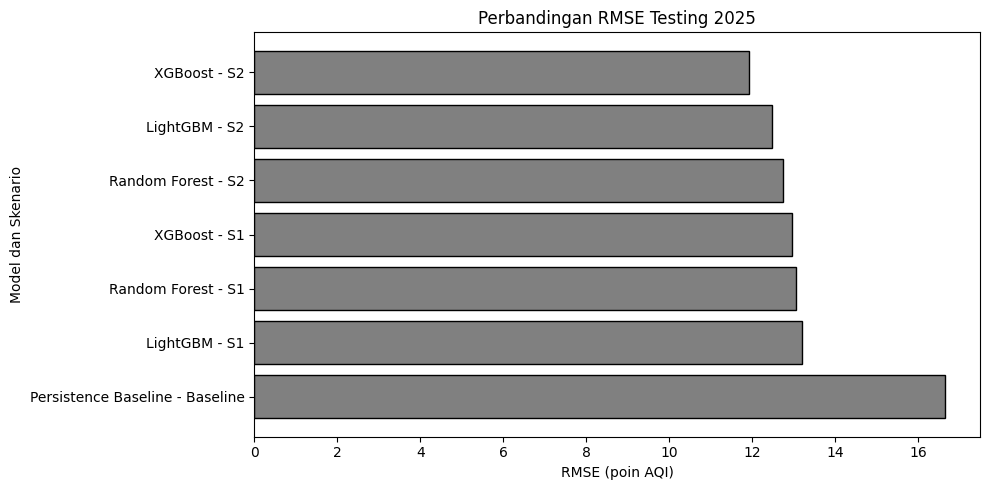

In [63]:
# Cell 9.3 - Grafik RMSE testing 2025

import matplotlib.pyplot as plt

grafik = df_perbandingan_final.copy()

grafik["Nama"] = (
    grafik["Model"] + " - " + grafik["Skenario"]
)

plt.figure(figsize=(10, 5))

plt.barh(
    grafik["Nama"],
    grafik["RMSE"],
    color="gray",
    edgecolor="black"
)

plt.xlabel("RMSE (poin AQI)")
plt.ylabel("Model dan Skenario")
plt.title("Perbandingan RMSE Testing 2025")

plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()


In [64]:
# Cell 9.4 - Dampak penambahan fitur meteorologi

df_meteorologi = df_hasil_testing.pivot(
    index="Model",
    columns="Skenario",
    values="RMSE"
).copy()

df_meteorologi["Selisih_S2_minus_S1"] = (
    df_meteorologi["S2"] - df_meteorologi["S1"]
)

df_meteorologi["Perubahan_RMSE_%"] = (
    df_meteorologi["Selisih_S2_minus_S1"]
    / df_meteorologi["S1"]
    * 100
)

display(df_meteorologi.round(4))


Skenario,S1,S2,Selisih_S2_minus_S1,Perubahan_RMSE_%
Model,,,,
LightGBM,13.1980,12.4665,-0.7315,-5.5426
Random Forest,13.0543,12.7453,-0.3090,-2.3672
XGBoost,12.9490,11.9138,-1.0353,-7.9951


In [65]:
# Cell 9.5 - Menyimpan hasil evaluasi

df_perbandingan_final.to_csv(
    "Perbandingan_Model_dan_Baseline_2025.csv",
    index=False
)

df_improvement.to_csv(
    "Improvement_Terhadap_Baseline_2025.csv",
    index=False
)

df_meteorologi.to_csv(
    "Dampak_Fitur_Meteorologi_2025.csv"
)

print("Semua hasil evaluasi berhasil disimpan!")


Semua hasil evaluasi berhasil disimpan!


# 10. Feature Importance

mengukur seberapa penting variabel untuk prediksi model.
kalau RMSE meningkat banyak setelah fitur diacak, jadi modelnya cukup bergantung pada fitur trsbut

In [66]:
# Cell 10.1 - Model XGBoost S2 untuk feature importance

from sklearn.inspection import permutation_importance
import pandas as pd
import numpy as np

# Mengambil hyperparameter terbaik dari tuning
baris_xgb_s2 = df_ringkasan_tuning[
    (df_ringkasan_tuning["Model"] == "XGBoost") &
    (df_ringkasan_tuning["Skenario"] == "S2")
].iloc[0]

params_xgb_s2 = baris_xgb_s2["Best_Parameters"]

# Melatih model menggunakan training saja
model_importance = buat_model(
    "XGBoost",
    params_xgb_s2
)

model_importance.fit(
    X_train_s2,
    y_train
)

print("Model XGBoost S2 siap untuk analisis fitur.")
print("Hyperparameter:", params_xgb_s2)


Model XGBoost S2 siap untuk analisis fitur.
Hyperparameter: {'n_estimators': 100, 'max_depth': 3, 'learning_rate': 0.05}


In [67]:
# Cell 10.2 - Menghitung permutation importance

hasil_importance = permutation_importance(
    estimator=model_importance,
    X=X_val_s2,
    y=y_val,
    scoring="neg_root_mean_squared_error",
    n_repeats=10,
    random_state=42,
    n_jobs=-1
)

df_importance = pd.DataFrame({
    "Fitur": X_val_s2.columns,
    "Importance_Mean": hasil_importance.importances_mean,
    "Importance_Std": hasil_importance.importances_std
})

df_importance = df_importance.sort_values(
    by="Importance_Mean",
    ascending=False
).reset_index(drop=True)

display(df_importance.round(4))


,Fitur,Importance_Mean,Importance_Std
0,PM25_lag0,40.3083,1.6015
1,PM10_lag0,9.1175,0.6006
2,Hujan_lag0,1.2036,0.2022
3,Angin_lag0,0.9228,0.1393
4,AQI_lag2,0.5242,0.0445
5,PM25_lag2,0.4351,0.0951
6,Suhu_lag1,0.1676,0.0429
7,Suhu_lag2,0.1035,0.0381
8,AQI_lag1,0.0503,0.0216
9,Hujan_lag1,-0.0036,0.0080


setiap fitur diacak 10 kali kemudian, kalau nilai nya positif besar itu berguna untuk model, kalau mendekati 0 barti tidak banyak memengaruhi.

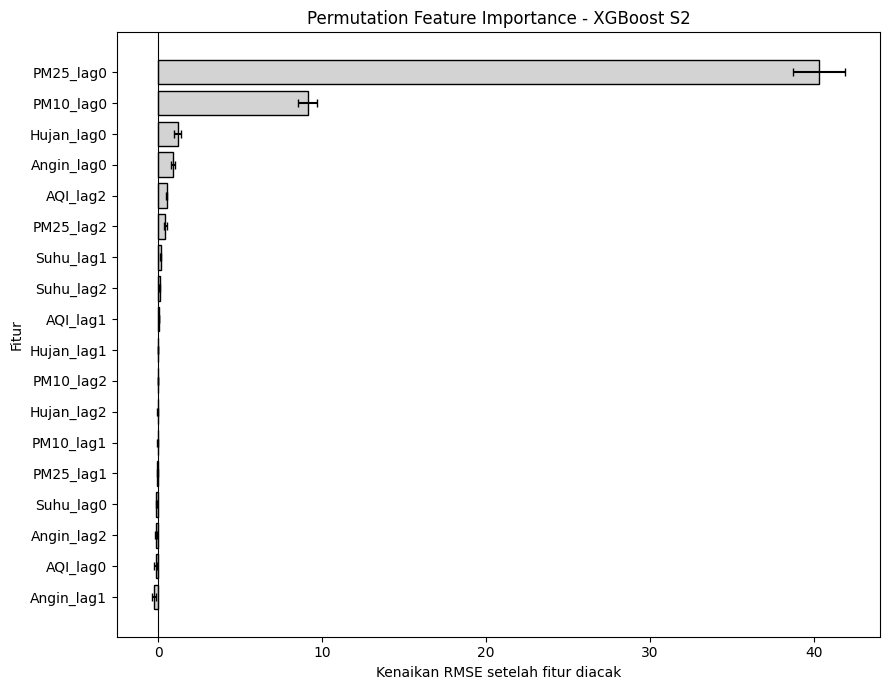

In [68]:
# Cell 10.3 - Grafik permutation feature importance

import matplotlib.pyplot as plt

df_plot = df_importance.sort_values(
    by="Importance_Mean",
    ascending=True
)

plt.figure(figsize=(9, 7))

plt.barh(
    df_plot["Fitur"],
    df_plot["Importance_Mean"],
    xerr=df_plot["Importance_Std"],
    color="lightgray",
    edgecolor="black",
    capsize=3
)

plt.axvline(0, color="black", linewidth=0.8)

plt.xlabel("Kenaikan RMSE setelah fitur diacak")
plt.ylabel("Fitur")
plt.title("Permutation Feature Importance - XGBoost S2")

plt.tight_layout()
plt.show()


In [69]:
# Cell 10.4 - Importance berdasarkan kelompok variabel

def kelompok_fitur(nama_fitur):
    return nama_fitur.split("_lag")[0]

df_importance["Kelompok"] = (
    df_importance["Fitur"].apply(kelompok_fitur)
)

df_kelompok = (
    df_importance
    .groupby("Kelompok", as_index=False)
    .agg(
        Total_Importance=("Importance_Mean", "sum")
    )
    .sort_values(
        "Total_Importance",
        ascending=False
    )
)

display(df_kelompok.round(4))


,Kelompok,Total_Importance
4,PM25,40.7002
3,PM10,9.0877
2,Hujan,1.1786
1,Angin,0.5274
0,AQI,0.4202
5,Suhu,0.1757


In [70]:
# Cell 10.5 - Fokus pada fitur meteorologi

df_meteorologi_importance = df_importance[
    df_importance["Kelompok"].isin(
        ["Suhu", "Hujan", "Angin"]
    )
].copy()

display(
    df_meteorologi_importance[
        ["Fitur", "Importance_Mean", "Importance_Std"]
    ].round(4)
)


,Fitur,Importance_Mean,Importance_Std
2,Hujan_lag0,1.2036,0.2022
3,Angin_lag0,0.9228,0.1393
6,Suhu_lag1,0.1676,0.0429
7,Suhu_lag2,0.1035,0.0381
9,Hujan_lag1,-0.0036,0.0080
11,Hujan_lag2,-0.0214,0.0469
14,Suhu_lag0,-0.0954,0.0308
15,Angin_lag2,-0.1365,0.0762
17,Angin_lag1,-0.2589,0.1268


# 11. Analisis Residual dan Visualisasi Hasil Forecasting AQI 2025.

In [71]:
# Cell 11.1 - Data aktual, prediksi, dan residual XGBoost S2

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

df_residual = pd.DataFrame({
    "Tanggal": y_test.index + pd.Timedelta(days=1),
    "AQI_Aktual": y_test.to_numpy(),
    "AQI_Prediksi": prediksi_final[("XGBoost", "S2")]
})

df_residual["Residual"] = (
    df_residual["AQI_Aktual"] -
    df_residual["AQI_Prediksi"]
)

df_residual["Absolute_Error"] = (
    df_residual["Residual"].abs()
)

df_residual = df_residual.sort_values(
    "Tanggal"
).reset_index(drop=True)

print("Jumlah data:", len(df_residual))
display(df_residual.head(10))


Jumlah data: 365


,Tanggal,AQI_Aktual,AQI_Prediksi,Residual,Absolute_Error
0,2025-01-01,160.50,159.343567,1.156433,1.156433
1,2025-01-02,161.88,158.893494,2.986506,2.986506
2,2025-01-03,167.29,159.638916,7.651084,7.651084
3,2025-01-04,177.04,174.461533,2.578467,2.578467
4,2025-01-05,163.79,168.855804,-5.065804,5.065804
5,2025-01-06,156.96,158.269257,-1.309257,1.309257
6,2025-01-07,163.54,156.361542,7.178458,7.178458
7,2025-01-08,163.83,162.653961,1.176039,1.176039
8,2025-01-09,166.38,162.387329,3.992671,3.992671
9,2025-01-10,166.25,160.679855,5.570145,5.570145


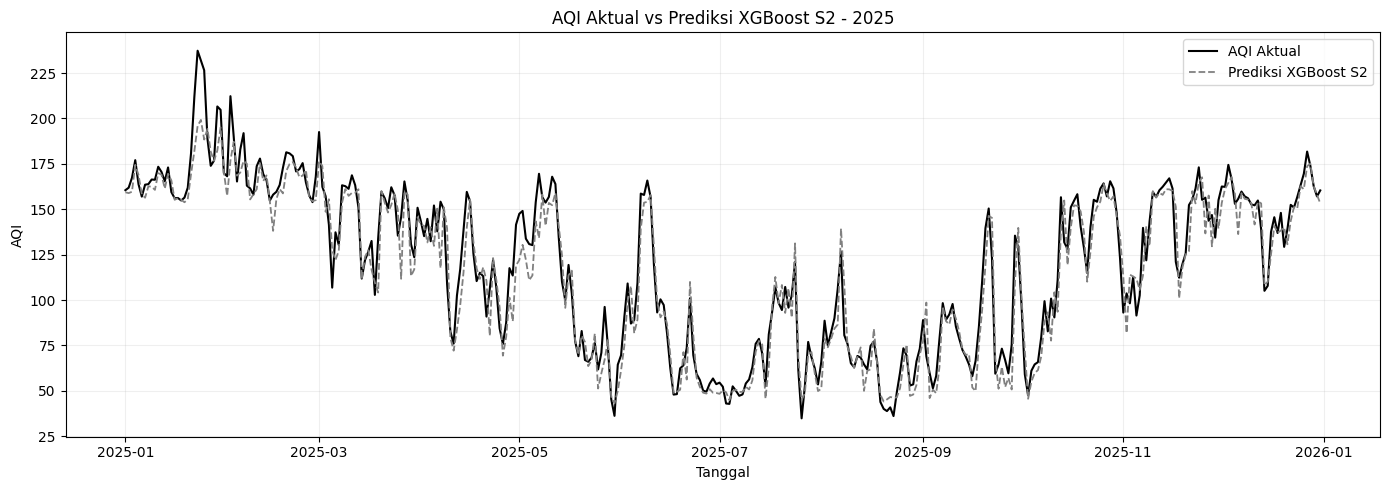

In [72]:
# Cell 11.2 - Grafik aktual vs prediksi AQI 2025

plt.figure(figsize=(14, 5))

plt.plot(
    df_residual["Tanggal"],
    df_residual["AQI_Aktual"],
    label="AQI Aktual",
    color="black",
    linewidth=1.5
)

plt.plot(
    df_residual["Tanggal"],
    df_residual["AQI_Prediksi"],
    label="Prediksi XGBoost S2",
    color="gray",
    linestyle="--",
    linewidth=1.3
)

plt.xlabel("Tanggal")
plt.ylabel("AQI")
plt.title("AQI Aktual vs Prediksi XGBoost S2 - 2025")
plt.legend()
plt.grid(alpha=0.2)
plt.tight_layout()
plt.show()


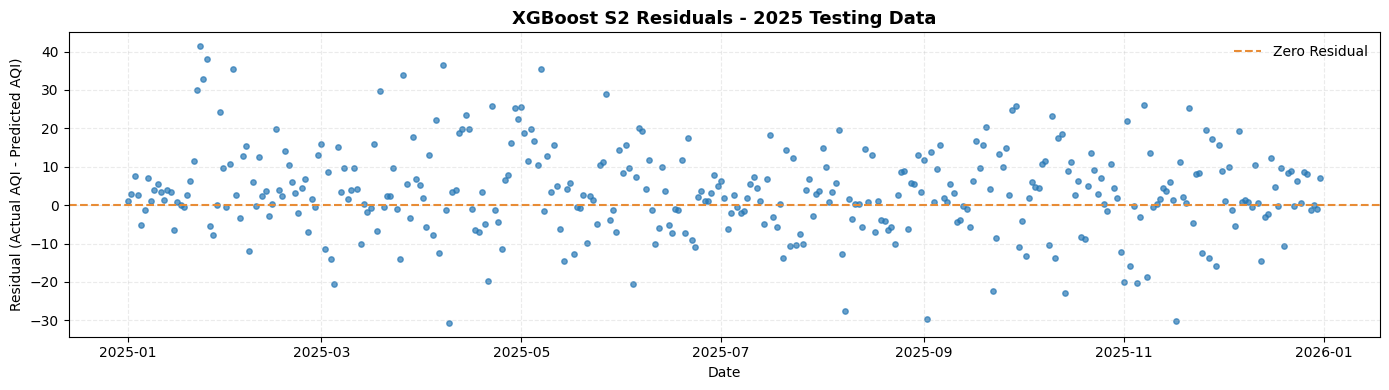

In [73]:

# Cell 11.3 - Residual Plot Over Time

plt.figure(figsize=(14, 4))

plt.scatter(
    df_residual["Tanggal"],
    df_residual["Residual"],
    color="#2878B5",
    s=15,
    alpha=0.7
)

plt.axhline(
    y=0,
    color="#E88C36",
    linestyle="--",
    linewidth=1.5,
    label="Zero Residual"
)

plt.xlabel("Date", fontsize=10)
plt.ylabel("Residual (Actual AQI - Predicted AQI)", fontsize=10)

plt.title(
    "XGBoost S2 Residuals - 2025 Testing Data",
    fontsize=13,
    fontweight="bold"
)

plt.grid(True, linestyle="--", alpha=0.25)
plt.legend(frameon=False)
plt.tight_layout()
plt.show()


Titik di atas nol menunjukkan model memprediksi AQI terlalu rendah. Titik di bawah nol menunjukkan model memprediksi terlalu tinggi.

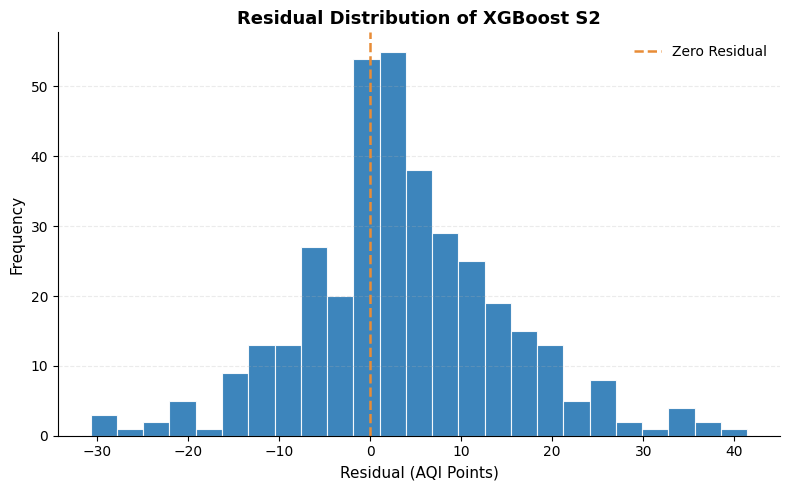

In [74]:

# Cell 11.4 - XGBoost S2 Residual Distribution

plt.figure(figsize=(8, 5))

plt.hist(
    df_residual["Residual"],
    bins=25,
    color="#2878B5",
    edgecolor="white",
    linewidth=0.8,
    alpha=0.9
)

plt.axvline(
    x=0,
    color="#E88C36",
    linestyle="--",
    linewidth=1.8,
    label="Zero Residual"
)

plt.xlabel("Residual (AQI Points)", fontsize=11)
plt.ylabel("Frequency", fontsize=11)

plt.title(
    "Residual Distribution of XGBoost S2",
    fontsize=13,
    fontweight="bold"
)

plt.legend(frameon=False)
plt.grid(axis="y", linestyle="--", alpha=0.25)
plt.gca().spines["top"].set_visible(False)
plt.gca().spines["right"].set_visible(False)

plt.tight_layout()
plt.show()


In [75]:
# Cell 11.5 - Statistik residual

ringkasan_residual = pd.DataFrame({
    "Statistik": [
        "Mean Residual (Bias)",
        "Median Residual",
        "MAE",
        "RMSE",
        "Residual Minimum",
        "Residual Maksimum",
        "Kesalahan Absolut Maksimum"
    ],
    "Nilai": [
        df_residual["Residual"].mean(),
        df_residual["Residual"].median(),
        df_residual["Absolute_Error"].mean(),
        np.sqrt(np.mean(df_residual["Residual"]**2)),
        df_residual["Residual"].min(),
        df_residual["Residual"].max(),
        df_residual["Absolute_Error"].max()
    ]
})

display(ringkasan_residual.round(4))


,Statistik,Nilai
0,Mean Residual (Bias),3.6487
1,Median Residual,2.7707
2,MAE,8.8454
3,RMSE,11.9138
4,Residual Minimum,-30.6848
5,Residual Maksimum,41.4186
6,Kesalahan Absolut Maksimum,41.4186


In [76]:
# Cell 11.6 - Sepuluh prediksi dengan kesalahan terbesar

df_kesalahan_terbesar = df_residual.nlargest(
    10, "Absolute_Error"
)

display(
    df_kesalahan_terbesar[
        [
            "Tanggal",
            "AQI_Aktual",
            "AQI_Prediksi",
            "Residual",
            "Absolute_Error"
        ]
    ].round(4)
)


,Tanggal,AQI_Aktual,AQI_Prediksi,Residual,Absolute_Error
22,2025-01-23,237.33,195.911407,41.4186,41.4186
24,2025-01-25,226.58,188.397202,38.1828,38.1828
96,2025-04-07,154.17,117.601097,36.5689,36.5689
126,2025-05-07,169.54,134.087296,35.4527,35.4527
32,2025-02-02,212.29,176.859207,35.4307,35.4307
84,2025-03-26,145.75,111.715401,34.0346,34.0346
23,2025-01-24,232.04,199.207703,32.8323,32.8323
98,2025-04-09,108.79,139.474792,-30.6848,30.6848
320,2025-11-17,121.00,151.258606,-30.2586,30.2586
21,2025-01-22,211.71,181.827103,29.8829,29.8829


In [77]:
# Cell 11.7 - Menyimpan data prediksi dan residual

df_residual.to_csv(
    "Prediksi_dan_Residual_XGBoost_S2_2025.csv",
    index=False
)

ringkasan_residual.to_csv(
    "Ringkasan_Residual_XGBoost_S2_2025.csv",
    index=False
)

print("Hasil analisis residual berhasil disimpan!")


Hasil analisis residual berhasil disimpan!


# 12. Analisis Nilai Tambah Fitur Meteorologi (Incremental Predictive Value).

Apakah menambahkan fitur meteorologi benar-benar membuat prediksi AQI hari berikutnya lebih baik?

In [78]:
# Cell 12.1 - Selisih kesalahan harian S1 dan S2

import pandas as pd
import numpy as np

hasil_error_harian = {}

for nama_model in ["Random Forest", "XGBoost", "LightGBM"]:

    aktual = y_test.to_numpy()

    pred_s1 = np.asarray(
        prediksi_final[(nama_model, "S1")]
    )

    pred_s2 = np.asarray(
        prediksi_final[(nama_model, "S2")]
    )

    tabel = pd.DataFrame({
        "Tanggal": y_test.index + pd.Timedelta(days=1),
        "AQI_Aktual": aktual,
        "Error_S1": np.abs(aktual - pred_s1),
        "Error_S2": np.abs(aktual - pred_s2)
    })

    tabel["Perbaikan_Error"] = (
        tabel["Error_S1"] - tabel["Error_S2"]
    )

    hasil_error_harian[nama_model] = tabel

print("Selisih kesalahan harian berhasil dihitung.")


Selisih kesalahan harian berhasil dihitung.


In [79]:
# Cell 12.2 - Konsistensi peningkatan performa S2

ringkasan_harian = []

for nama_model, tabel in hasil_error_harian.items():

    lebih_baik = (tabel["Perbaikan_Error"] > 0).sum()
    lebih_buruk = (tabel["Perbaikan_Error"] < 0).sum()
    sama = (tabel["Perbaikan_Error"] == 0).sum()

    ringkasan_harian.append({
        "Model": nama_model,
        "Hari_S2_Lebih_Baik": lebih_baik,
        "Hari_S2_Lebih_Buruk": lebih_buruk,
        "Hari_Sama": sama,
        "Persentase_S2_Lebih_Baik": (
            lebih_baik / len(tabel) * 100
        ),
        "Rata_Rata_Perbaikan_MAE": (
            tabel["Perbaikan_Error"].mean()
        )
    })

df_ringkasan_harian = pd.DataFrame(ringkasan_harian)

display(df_ringkasan_harian.round(4))


,Model,Hari_S2_Lebih_Baik,Hari_S2_Lebih_Buruk,Hari_Sama,Persentase_S2_Lebih_Baik,Rata_Rata_Perbaikan_MAE
0,Random Forest,189,176,0,51.7808,0.1688
1,XGBoost,227,138,0,62.1918,0.9999
2,LightGBM,220,145,0,60.2740,0.5696


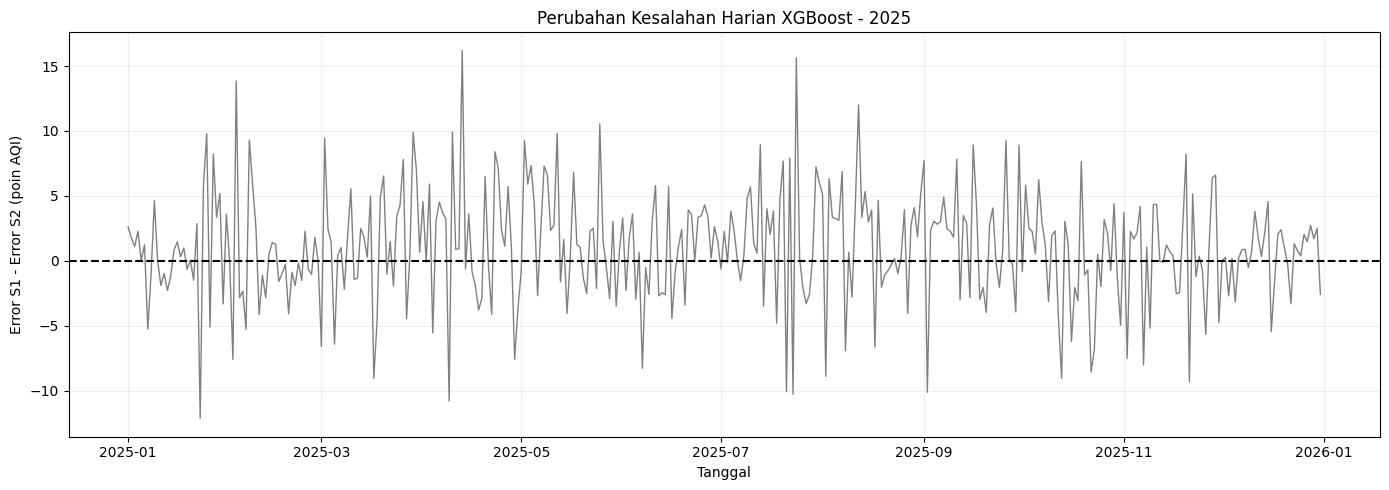

In [80]:
# Cell 12.3 - Perubahan kesalahan harian XGBoost

import matplotlib.pyplot as plt

df_xgb_error = hasil_error_harian["XGBoost"]

plt.figure(figsize=(14, 5))

plt.plot(
    df_xgb_error["Tanggal"],
    df_xgb_error["Perbaikan_Error"],
    color="gray",
    linewidth=1
)

plt.axhline(
    0,
    color="black",
    linestyle="--"
)

plt.xlabel("Tanggal")
plt.ylabel("Error S1 - Error S2 (poin AQI)")
plt.title("Perubahan Kesalahan Harian XGBoost - 2025")
plt.grid(alpha=0.2)
plt.tight_layout()
plt.show()


Nilai di atas nol menunjukkan hari ketika XGBoost S2 lebih akurat, sedangkan nilai di bawah nol menunjukkan hari ketika S1 lebih akurat.

In [81]:
# Cell 12.4 - Ringkasan nilai tambah meteorologi

ringkasan_incremental = []

for nama_model in ["Random Forest", "XGBoost", "LightGBM"]:

    data_model = df_hasil_testing[
        df_hasil_testing["Model"] == nama_model
    ].set_index("Skenario")

    mae_s1 = data_model.loc["S1", "MAE"]
    mae_s2 = data_model.loc["S2", "MAE"]

    rmse_s1 = data_model.loc["S1", "RMSE"]
    rmse_s2 = data_model.loc["S2", "RMSE"]

    ringkasan_incremental.append({
        "Model": nama_model,
        "Penurunan_MAE_%": (
            (mae_s1 - mae_s2) / mae_s1 * 100
        ),
        "Penurunan_RMSE_%": (
            (rmse_s1 - rmse_s2) / rmse_s1 * 100
        )
    })

df_incremental = pd.DataFrame(ringkasan_incremental)

display(df_incremental.round(4))


,Model,Penurunan_MAE_%,Penurunan_RMSE_%
0,Random Forest,1.7081,2.3672
1,XGBoost,10.1563,7.9951
2,LightGBM,5.6766,5.5426


In [82]:
# Cell 12.5 - Menyimpan hasil analisis incremental

df_ringkasan_harian.to_csv(
    "Konsistensi_Peningkatan_Meteorologi_2025.csv",
    index=False
)

df_incremental.to_csv(
    "Incremental_Predictive_Value_2025.csv",
    index=False
)

for nama_model, tabel in hasil_error_harian.items():

    nama_file = nama_model.replace(" ", "_")

    tabel.to_csv(
        f"Error_Harian_{nama_file}_2025.csv",
        index=False
    )

print("Seluruh hasil analisis incremental berhasil disimpan!")


Seluruh hasil analisis incremental berhasil disimpan!


# 13. Hasil

In [83]:
# CELL 14.1 - Tabel hasil evaluasi final

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

urutan_model = ["Random Forest", "XGBoost", "LightGBM"]

tabel_hasil = df_hasil_testing[
    ["Model", "Skenario", "MAE", "RMSE", "R2"]
].copy()

tabel_hasil["Model"] = pd.Categorical(
    tabel_hasil["Model"],
    categories=urutan_model,
    ordered=True
)

tabel_hasil = tabel_hasil.sort_values(
    ["Model", "Skenario"]
).reset_index(drop=True)

display(tabel_hasil.round(4))


,Model,Skenario,MAE,RMSE,R2
0,Random Forest,S1,9.8815,13.0543,0.9150
1,Random Forest,S2,9.7128,12.7453,0.9190
2,XGBoost,S1,9.8453,12.9490,0.9164
3,XGBoost,S2,8.8454,11.9138,0.9292
4,LightGBM,S1,10.0344,13.1980,0.9131
5,LightGBM,S2,9.4648,12.4665,0.9225


In [84]:
# CELL 14.2 - Nilai tambah fitur meteorologi

hasil_perubahan = []

for model in urutan_model:

    d = df_hasil_testing[
        df_hasil_testing["Model"] == model
    ].set_index("Skenario")

    hasil_perubahan.append({
        "Model": model,
        "MAE_S1": d.loc["S1", "MAE"],
        "MAE_S2": d.loc["S2", "MAE"],
        "Penurunan_MAE_%": (
            (d.loc["S1", "MAE"] - d.loc["S2", "MAE"])
            / d.loc["S1", "MAE"] * 100
        ),
        "RMSE_S1": d.loc["S1", "RMSE"],
        "RMSE_S2": d.loc["S2", "RMSE"],
        "Penurunan_RMSE_%": (
            (d.loc["S1", "RMSE"] - d.loc["S2", "RMSE"])
            / d.loc["S1", "RMSE"] * 100
        ),
        "R2_S1": d.loc["S1", "R2"],
        "R2_S2": d.loc["S2", "R2"],
        "Selisih_R2": (
            d.loc["S2", "R2"] - d.loc["S1", "R2"]
        )
    })

tabel_perubahan = pd.DataFrame(hasil_perubahan)

display(tabel_perubahan.round(4))


,Model,MAE_S1,MAE_S2,Penurunan_MAE_%,RMSE_S1,RMSE_S2,Penurunan_RMSE_%,R2_S1,R2_S2,Selisih_R2
0,Random Forest,9.8815,9.7128,1.7081,13.0543,12.7453,2.3672,0.9150,0.9190,0.0040
1,XGBoost,9.8453,8.8454,10.1563,12.9490,11.9138,7.9951,0.9164,0.9292,0.0128
2,LightGBM,10.0344,9.4648,5.6766,13.1980,12.4665,5.5426,0.9131,0.9225,0.0094


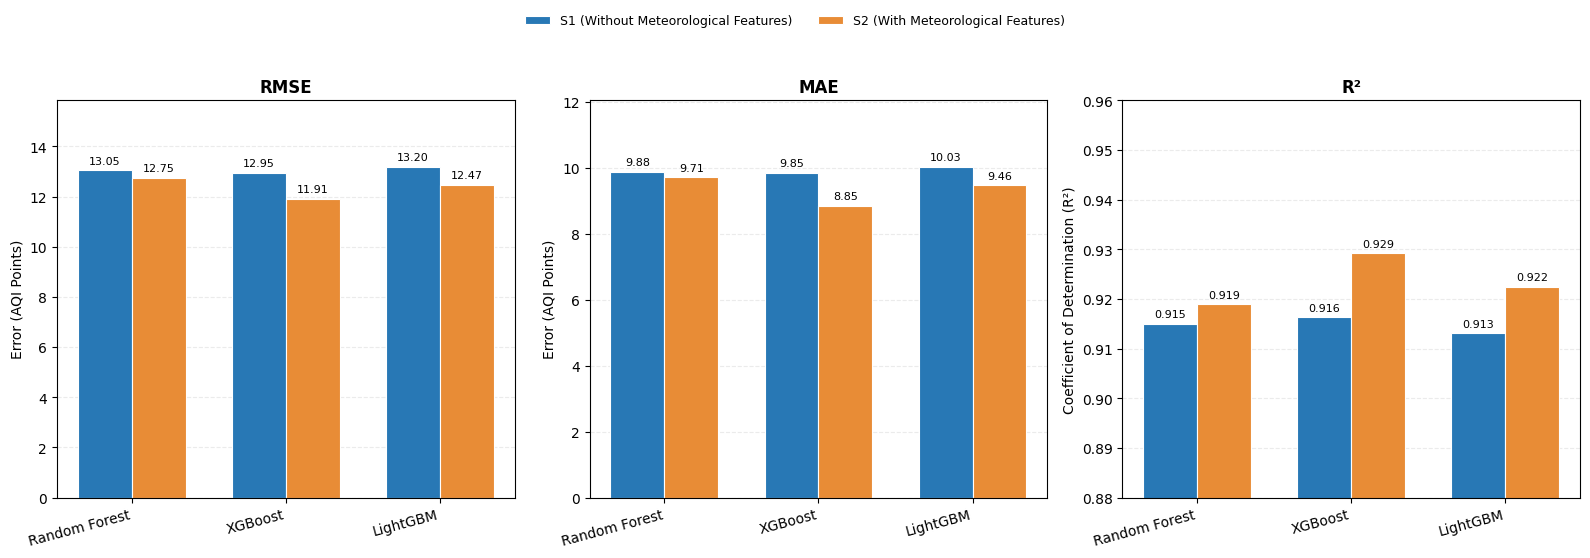

In [85]:

# CELL 14.3 - Three-Panel Model Performance Comparison

fig, axes = plt.subplots(1, 3, figsize=(16, 5))

for ax, metrik in zip(axes, ["RMSE", "MAE", "R2"]):
    pivot = df_hasil_testing.pivot(
        index="Model",
        columns="Skenario",
        values=metrik
    ).reindex(urutan_model)

    x = np.arange(len(urutan_model))
    lebar = 0.35

    b1 = ax.bar(
        x - lebar/2,
        pivot["S1"],
        lebar,
        label="S1 (Without Meteorological Features)",
        color="#2878B5",
        edgecolor="white",
        linewidth=0.8
    )

    b2 = ax.bar(
        x + lebar/2,
        pivot["S2"],
        lebar,
        label="S2 (With Meteorological Features)",
        color="#E88C36",
        edgecolor="white",
        linewidth=0.8
    )

    ax.set_title(
        metrik if metrik != "R2" else "R²",
        fontsize=12,
        fontweight="bold"
    )

    ax.set_xticks(x)
    ax.set_xticklabels(
        ["Random Forest", "XGBoost", "LightGBM"],
        rotation=15,
        ha="right"
    )

    ax.grid(axis="y", linestyle="--", alpha=0.25)
    ax.set_axisbelow(True)

    if metrik == "R2":
        ax.set_ylim(0.88, 0.96)
        fmt = "%.3f"
    else:
        ax.set_ylim(0, pivot.max().max() * 1.2)
        fmt = "%.2f"

    ax.bar_label(b1, fmt=fmt, padding=3, fontsize=8)
    ax.bar_label(b2, fmt=fmt, padding=3, fontsize=8)

axes[0].set_ylabel("Error (AQI Points)", fontsize=10)
axes[1].set_ylabel("Error (AQI Points)", fontsize=10)
axes[2].set_ylabel("Coefficient of Determination (R²)", fontsize=10)

fig.legend(
    ["S1 (Without Meteorological Features)",
     "S2 (With Meteorological Features)"],
    loc="upper center",
    ncol=2,
    bbox_to_anchor=(0.5, 1.12),
    frameon=False,
    fontsize=9
)

plt.tight_layout()

plt.savefig(
    "Figure_1_Model_Performance_Comparison.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


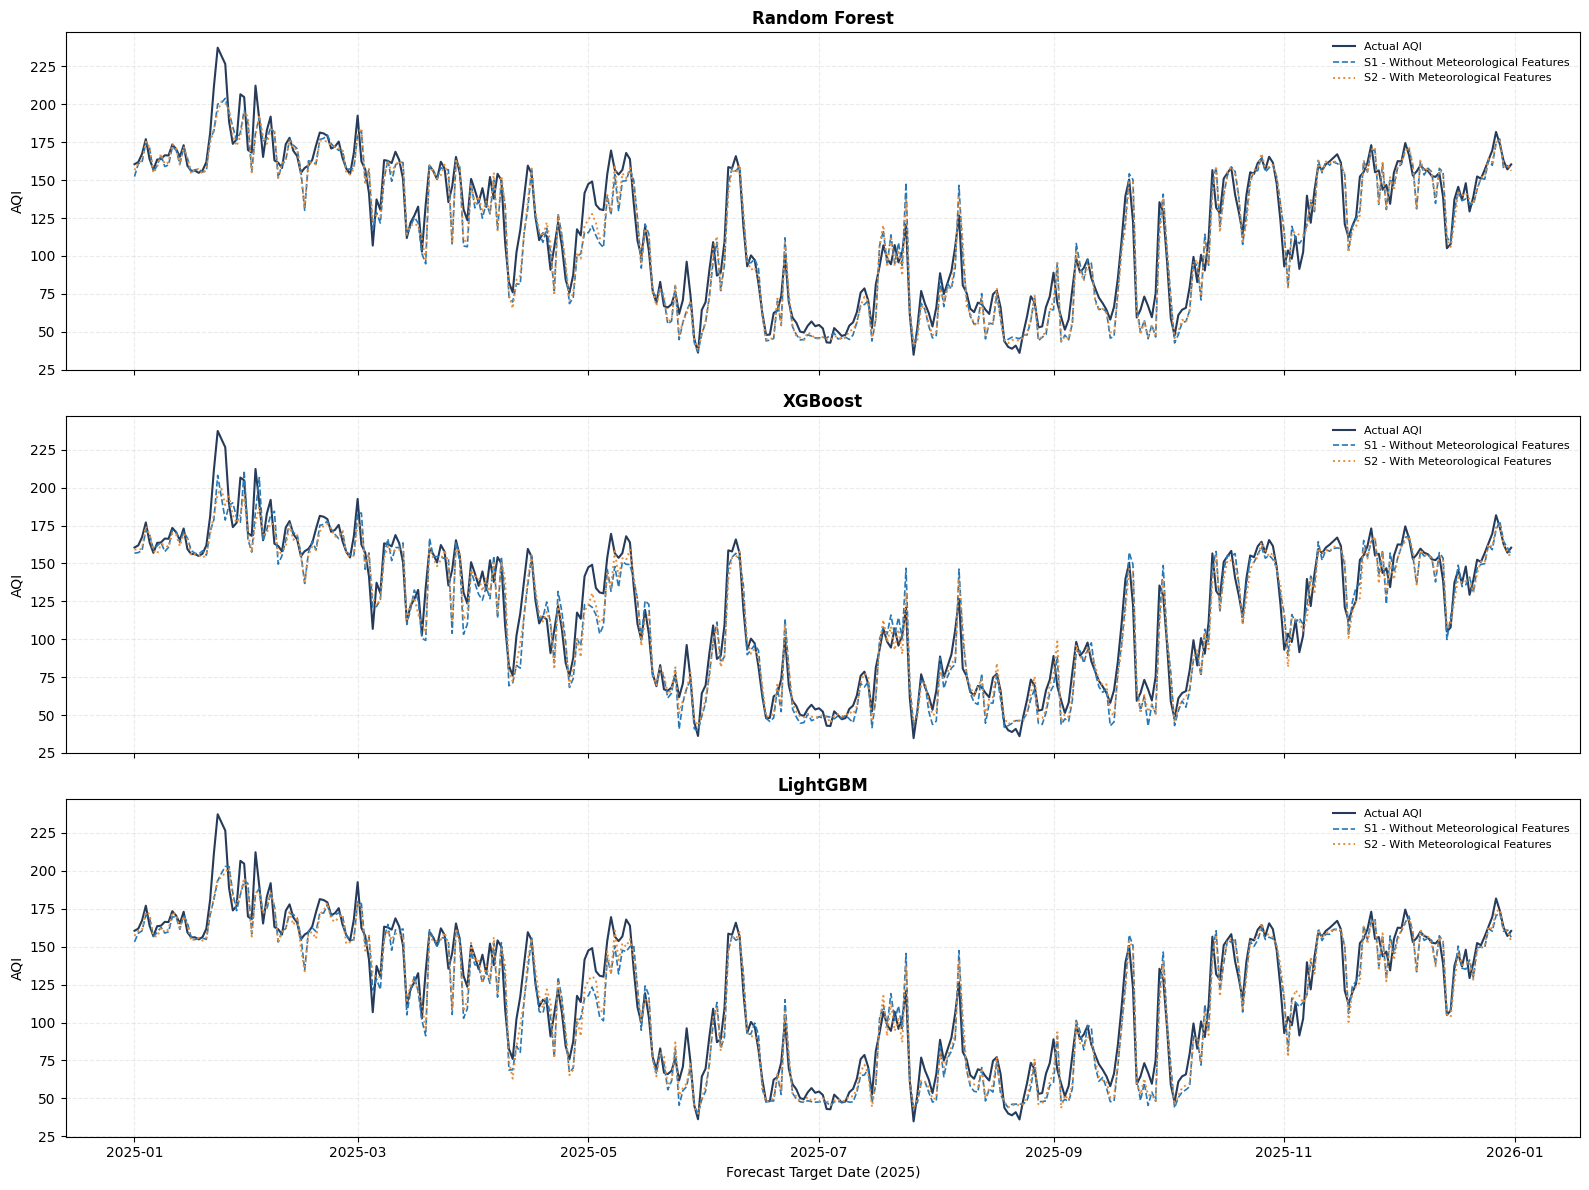

In [86]:

# CELL 14.4 - Actual vs. Predicted AQI

tanggal = y_test.index + pd.Timedelta(days=1)
aktual = y_test.to_numpy()

fig, axes = plt.subplots(
    3, 1,
    figsize=(16, 12),
    sharex=True,
    sharey=True
)

for ax, model in zip(axes, urutan_model):

    ax.plot(
        tanggal, aktual,
        color="#263B5A",
        linewidth=1.5,
        label="Actual AQI"
    )

    ax.plot(
        tanggal,
        prediksi_final[(model, "S1")],
        color="#2878B5",
        linestyle="--",
        linewidth=1.2,
        label="S1 - Without Meteorological Features"
    )

    ax.plot(
        tanggal,
        prediksi_final[(model, "S2")],
        color="#E88C36",
        linestyle=":",
        linewidth=1.4,
        label="S2 - With Meteorological Features"
    )

    ax.set_title(model, fontsize=12, fontweight="bold")
    ax.set_ylabel("AQI", fontsize=10)
    ax.grid(True, linestyle="--", alpha=0.25)
    ax.legend(loc="upper right", fontsize=8, frameon=False)

axes[-1].set_xlabel("Forecast Target Date (2025)", fontsize=10)

plt.tight_layout()

plt.savefig(
    "Figure_2_Actual_vs_Predicted.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


In [87]:

# CELL 14.5 - Permutation importance 3 model S2

from sklearn.inspection import permutation_importance

hasil_importance_model = {}

for model in urutan_model:

    baris = df_ringkasan_tuning[
        (df_ringkasan_tuning["Model"] == model) &
        (df_ringkasan_tuning["Skenario"] == "S2")
    ].iloc[0]

    params = baris["Best_Parameters"]

    model_pi = buat_model(model, params)
    model_pi.fit(X_train_s2, y_train)

    pi = permutation_importance(
        model_pi,
        X_val_s2,
        y_val,
        scoring="neg_root_mean_squared_error",
        n_repeats=10,
        random_state=42,
        n_jobs=-1
    )

    tabel = pd.DataFrame({
        "Fitur": X_val_s2.columns,
        "Importance_Mean": pi.importances_mean,
        "Importance_Std": pi.importances_std
    }).sort_values(
        "Importance_Mean", ascending=False
    )

    hasil_importance_model[model] = tabel

    print(f"Selesai: {model}")

print("Permutation importance ketiga model selesai.")


Selesai: Random Forest
Selesai: XGBoost
Selesai: LightGBM
Permutation importance ketiga model selesai.


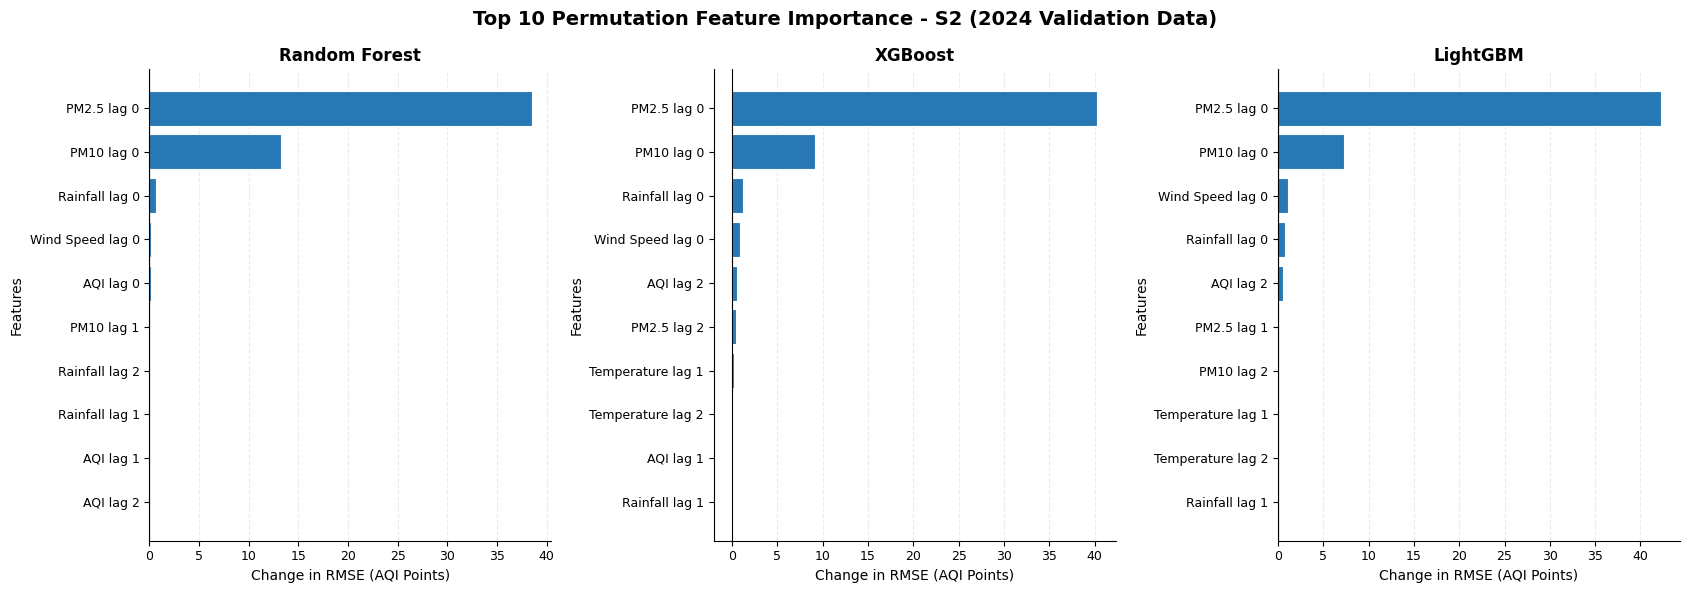

In [88]:

# CELL 14.6 - Top 10 Permutation Feature Importance (Three Panels)

fig, axes = plt.subplots(1, 3, figsize=(17, 6))

for ax, model in zip(axes, urutan_model):

    top10 = hasil_importance_model[model].head(10)
    top10 = top10.sort_values("Importance_Mean")

    # Translate feature names into English
    feature_labels = (
        top10["Fitur"]
        .str.replace("_", " ", regex=False)
        .str.replace("PM25", "PM2.5", regex=False)
        .str.replace("Suhu", "Temperature", regex=False)
        .str.replace("Hujan", "Rainfall", regex=False)
        .str.replace("Angin maks", "Maximum Wind Speed", regex=False)
        .str.replace("Angin", "Wind Speed", regex=False)
        .str.replace(r"lag(\d+)", r"lag \1", regex=True)
    )

    ax.barh(
        feature_labels,
        top10["Importance_Mean"],
        color="#2878B5",
        edgecolor="white",
        linewidth=0.8
    )

    ax.axvline(0, color="black", linewidth=0.8)
    ax.set_title(model, fontsize=12, fontweight="bold")
    ax.set_xlabel("Change in RMSE (AQI Points)", fontsize=10)
    ax.set_ylabel("Features", fontsize=10)

    ax.grid(axis="x", linestyle="--", alpha=0.25)
    ax.set_axisbelow(True)

    ax.tick_params(axis="both", labelsize=9)
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)

plt.suptitle(
    "Top 10 Permutation Feature Importance - S2 (2024 Validation Data)",
    fontsize=14,
    fontweight="bold"
)

plt.tight_layout()

plt.savefig(
    "Figure_3_Feature_Importance.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


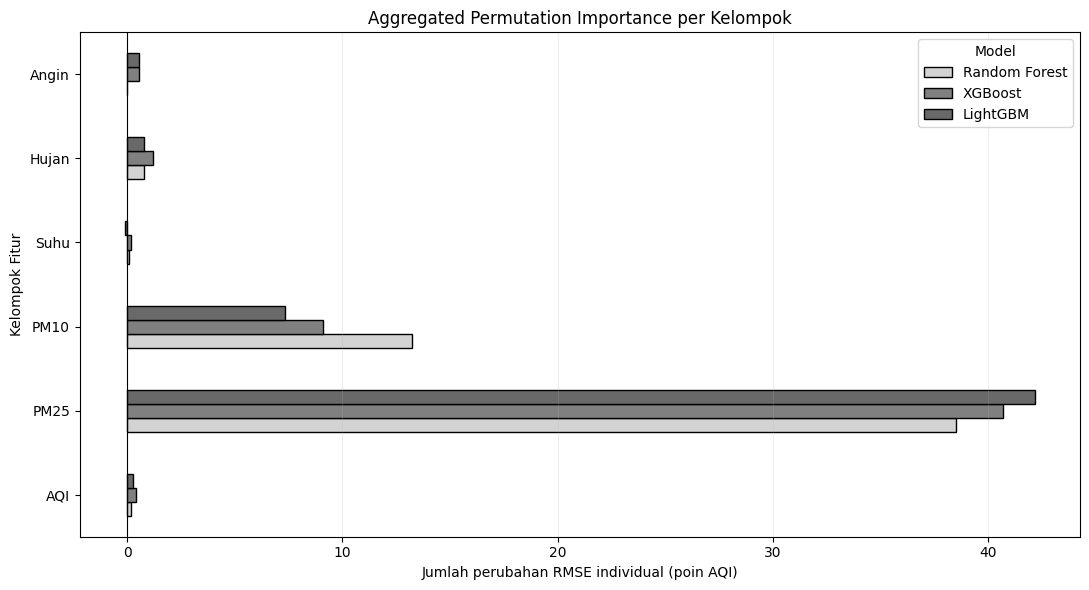

,Model,Kelompok,Importance
0,Random Forest,AQI,0.1850
1,Random Forest,PM25,38.5286
2,Random Forest,PM10,13.2541
3,Random Forest,Suhu,0.0715
4,Random Forest,Hujan,0.7555
5,Random Forest,Angin,-0.0206
6,XGBoost,AQI,0.4202
7,XGBoost,PM25,40.7002
8,XGBoost,PM10,9.0877
9,XGBoost,Suhu,0.1757


In [89]:

# CELL 14.7 - Aggregated permutation importance
# Jumlah importance tiap fitur dalam kelompok

kelompok_fitur = [
    "AQI", "PM25", "PM10",
    "Suhu", "Hujan", "Angin"
]

rekap_kelompok = []

for model in urutan_model:

    tabel = hasil_importance_model[model].copy()

    tabel["Kelompok"] = tabel["Fitur"].str.split(
        "_lag"
    ).str[0]

    agregat = tabel.groupby(
        "Kelompok"
    )["Importance_Mean"].sum()

    for kelompok in kelompok_fitur:

        rekap_kelompok.append({
            "Model": model,
            "Kelompok": kelompok,
            "Importance": agregat.get(kelompok, 0)
        })

df_importance_kelompok = pd.DataFrame(
    rekap_kelompok
)

pivot_kelompok = df_importance_kelompok.pivot(
    index="Kelompok",
    columns="Model",
    values="Importance"
).reindex(kelompok_fitur)

ax = pivot_kelompok[urutan_model].plot(
    kind="barh",
    figsize=(11, 6),
    color=["lightgray", "gray", "dimgray"],
    edgecolor="black"
)

ax.set_title(
    "Aggregated Permutation Importance per Kelompok"
)
ax.set_xlabel("Jumlah perubahan RMSE individual (poin AQI)")
ax.set_ylabel("Kelompok Fitur")
ax.axvline(0, color="black", linewidth=0.8)
ax.grid(axis="x", alpha=0.2)
ax.legend(title="Model")

plt.tight_layout()

plt.savefig(
    "Figure_4_Importance_Kelompok.png",
    dpi=300, bbox_inches="tight"
)

plt.show()

display(df_importance_kelompok.round(4))


In [90]:

# CELL 14.8 - Ekspor hasil final

with pd.ExcelWriter(
    "Hasil_Final_AQI_Dhaka_2025.xlsx"
) as writer:

    tabel_hasil.to_excel(
        writer, sheet_name="Evaluasi",
        index=False
    )

    tabel_perubahan.to_excel(
        writer, sheet_name="Nilai_Tambah",
        index=False
    )

    df_importance_kelompok.to_excel(
        writer, sheet_name="Importance_Kelompok",
        index=False
    )

    for model in urutan_model:

        hasil_importance_model[model].to_excel(
            writer,
            sheet_name=model.replace(" ", "_")[:31],
            index=False
        )

print("Tabel Excel berhasil disimpan.")
print("Keempat grafik juga sudah disimpan sebagai PNG.")


Tabel Excel berhasil disimpan.
Keempat grafik juga sudah disimpan sebagai PNG.


In [91]:

# CELL 14.9 - Peringkat model berdasarkan RMSE testing

peringkat_model = df_hasil_testing[
    ["Model", "Skenario", "MAE", "RMSE", "R2"]
].copy()

peringkat_model = peringkat_model.sort_values(
    "RMSE", ascending=True
).reset_index(drop=True)

peringkat_model.insert(
    0, "Peringkat",
    range(1, len(peringkat_model) + 1)
)

display(
    peringkat_model.style
    .format({
        "MAE": "{:.4f}",
        "RMSE": "{:.4f}",
        "R2": "{:.4f}"
    })
    .highlight_min(
        subset=["RMSE"],
        color="#dddddd"
    )
)

print("\nModel dengan RMSE testing terendah:")
print(
    peringkat_model.loc[
        0, ["Model", "Skenario", "MAE", "RMSE", "R2"]
    ]
)


,Peringkat,Model,Skenario,MAE,RMSE,R2
0,1,XGBoost,S2,8.8454,11.9138,0.9292
1,2,LightGBM,S2,9.4648,12.4665,0.9225
2,3,Random Forest,S2,9.7128,12.7453,0.9190
3,4,XGBoost,S1,9.8453,12.9490,0.9164
4,5,Random Forest,S1,9.8815,13.0543,0.9150
5,6,LightGBM,S1,10.0344,13.1980,0.9131



Model dengan RMSE testing terendah:
Model        XGBoost
Skenario          S2
MAE         8.845391
RMSE        11.91375
R2          0.929196
Name: 0, dtype: object


# 14. Analisis Tambahan untuk Revisi (Menjawab Komentar Reviewer)
Bagian ini **menambahkan** analisis yang diminta reviewer. Kode di bagian 1–13 di atas **tidak diubah**, dan hasil utamanya (RMSE, MAE, R² keenam model) tetap sama persis.
Bagian 14 membaca ulang dataset yang sama (`Dhaka_Climate_AQI_Data.csv`, sudah di-upload di Cell 1.2) dan menghasilkan semua angka baru untuk Tabel 2–7 serta Gambar 2–7 di naskah revisi.

| Sub-bagian | Isi | Komentar reviewer |
|---|---|---|
| 14.1–14.2 | Library dan versi, persiapan data | 24 (versi software) |
| 14.3 | Tuning ulang, uji 2025, baseline seasonal-naïve dan klimatologi, model linear ARX, kolom bias | 23, 28 |
| 14.4 | Uji Diebold–Mariano (HLN) dan block bootstrap | 23 |
| 14.5–14.7 | 10 seed, fixed-configuration ablation, rolling origin | 13, 23 |
| 14.8 | Breakdown musiman dan bias | 24 |
| 14.9 | Sensitivitas lag meteorologi dan cuaca hari target | 10 |
| 14.10 | Seleksi lag dengan inner split | 10 |
| 14.11 | Grouped permutation importance (validasi dan uji) | 21, 24, 31, 32 |
| 14.12 | Diagnostik sumber data (CAMS 49R1) | 37 |
| 14.13 | Sensitivitas lag polutan (kandidat C) | 10 |
| 14.14 | Ringkasan angka sesuai urutan naskah | – |
| 14.15 | Gambar 2–7 revisi (300 dpi) |  12, 29, 31, 33, 34, 35 |

In [152]:
# Cell 14.0 - Dataset location (GitHub)

import pandas as pd

CSV = "https://raw.githubusercontent.com/putriikrima2/Dhaka-AQI-Forecasting/refs/heads/main/data/Dhaka_Climate_AQI_Data.csv"

df_check = pd.read_csv(CSV)

print("Dataset berhasil dibaca:", df_check.shape)
print("Kolom:", df_check.columns.tolist())


Dataset berhasil dibaca: (1096, 10)
Kolom: ['Date', 'District', 'Latitude', 'Longitude', 'Avg_Temperature_C', 'Rainfall_mm', 'Max_Wind_Speed_kmh', 'PM10', 'PM2.5', 'AQI_Level']


## 14.1 Library dan versi software
Versi dicetak untuk dilaporkan di Bagian 2.7 naskah.

In [93]:
# Cell 14.1.1 - library dan versi software
import json, sys, platform, warnings, itertools
import numpy as np, pandas as pd
from scipy import stats
from sklearn.ensemble import RandomForestRegressor
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
warnings.filterwarnings("ignore")

BACKEND={}
try:
    from xgboost import XGBRegressor; import xgboost; BACKEND["xgb"]="xgboost "+xgboost.__version__
except ImportError:
    raise ImportError("Install xgboost: !pip install xgboost")
try:
    from lightgbm import LGBMRegressor; import lightgbm; BACKEND["lgb"]="lightgbm "+lightgbm.__version__
except ImportError:
    raise ImportError("Install lightgbm: !pip install lightgbm")
import sklearn; BACKEND["sklearn"]=sklearn.__version__; BACKEND["python"]=platform.python_version()
BACKEND["pandas"]=pd.__version__; BACKEND["numpy"]=np.__version__
print(BACKEND)

{'xgb': 'xgboost 3.4.1', 'lgb': 'lightgbm 4.6.0', 'sklearn': '1.6.1', 'python': '3.13.18', 'pandas': '2.2.3', 'numpy': '2.4.6'}


## 14.2 Data, feature engineering (lag 0–2), target AQI hari berikutnya, dan split kronologis
Train: target ≤ 30 Jun 2024 (544) · Validasi: Jul–Des 2024 (184) · Uji: 2025 (365). S1 = AQI, PM2.5, PM10 (9 fitur); S2 = S1 + suhu, hujan, angin (18 fitur).

In [137]:

# Cell 14.2.1 - Data preparation and model functions

df = pd.read_csv(CSV)
df["Date"] = pd.to_datetime(df["Date"])

data = df.set_index("Date").sort_index().asfreq("D")

COLS = {
    "AQI": "AQI_Level",
    "PM25": "PM2.5",
    "PM10": "PM10",
    "Temp": "Avg_Temperature_C",
    "Rain": "Rainfall_mm",
    "Wind": "Max_Wind_Speed_kmh"
}

POL = ("AQI", "PM25", "PM10")
METV = ("Temp", "Rain", "Wind")


# Feature engineering
def build(pl=(0, 1, 2), ml=(0, 1, 2), lead_met=False):

    fe = pd.DataFrame(index=data.index)

    for n, c in COLS.items():
        lags = pl if n in POL else ml

        for k in lags:
            fe[f"{n}_lag{k}"] = data[c].shift(k)

    if lead_met:
        for n in METV:
            fe[f"{n}_lead1"] = data[COLS[n]].shift(-1)

    fe["y"] = data["AQI_Level"].shift(-1)

    return fe


# Chronological data splitting
def masks(idx):

    tt = idx + pd.Timedelta(days=1)

    tr = tt <= pd.Timestamp("2024-06-30")
    va = (tt >= pd.Timestamp("2024-07-01")) & (tt <= pd.Timestamp("2024-12-31")
    )
    te = tt >= pd.Timestamp("2025-01-01")

    return np.asarray(tr), np.asarray(va), np.asarray(te)


# Define S1 and S2 features
S1 = [
    f"{v}_lag{k}"
    for v in POL
    for k in (0, 1, 2)
]

S2 = S1 + [
    f"{v}_lag{k}"
    for v in METV
    for k in (0, 1, 2)
]

fe = build().dropna()

tr, va, te = masks(fe.index)
trva = tr | va

y = fe["y"].values
tdate = fe.index + pd.Timedelta(days=1)


# Hyperparameter grid
GRID = {
    "RF": {
        "n_estimators": [150, 300],
        "max_depth": [10, 15],
        "min_samples_leaf": [2, 4]
    },

    "XGB": {
        "n_estimators": [100, 300, 500],
        "max_depth": [3, 5],
        "learning_rate": [0.01, 0.05, 0.1]
    },

    "LGB": {
        "n_estimators": [100, 300, 500],
        "num_leaves": [15, 31],
        "learning_rate": [0.01, 0.05, 0.1]
    }
}


# Model initialization
def make(alg, p, seed=42):

    if alg == "RF":
        return RandomForestRegressor(
            **p,
            random_state=seed,
            n_jobs=-1
        )

    if alg == "XGB":
        if "EMU" in BACKEND["xgb"]:
            return XGBEmu(**p)

        return XGBRegressor(
            **p,
            objective="reg:squarederror",
            random_state=seed,
            n_jobs=-1,
            verbosity=0
        )

    if alg == "LGB":
        if "EMU" in BACKEND["lgb"]:
            return HistGradientBoostingRegressor(
                max_iter=p["n_estimators"],
                max_leaf_nodes=p["num_leaves"],
                learning_rate=p["learning_rate"],
                min_samples_leaf=p.get("min_child_samples", 10),
                l2_regularization=0,
                max_bins=255,
                early_stopping=False,
                random_state=seed
            )

        q = dict(p)
        q.setdefault("min_child_samples", 10)

        return LGBMRegressor(
            **q,
            max_depth=-1,
            random_state=seed,
            n_jobs=-1,
            verbosity=-1
        )

    if alg == "ARX":
        return LinearRegression()


# Evaluation metrics
def rmse(a, b):
    return float(np.sqrt(mean_squared_error(a, b)))


def metrics(yt, yp):
    return {
        "MAE": float(mean_absolute_error(yt, yp)),
        "RMSE": rmse(yt, yp),
        "R2": float(r2_score(yt, yp)),
        "Bias": float(np.mean(yt - yp))
    }


# Hyperparameter combinations
def combos(alg):
    g = GRID[alg]

    return [
        dict(zip(g, v))
        for v in itertools.product(*g.values())
    ]


# Model fitting and prediction
def fitpred(alg, p, feats, trm, tem, seed=42):

    X = fe[feats].values
    model = make(alg, p, seed)

    model.fit(X[trm], y[trm])

    prediction = model.predict(X[tem])

    return prediction, model


# Initialize results
R = {"backend": BACKEND}

print("Cell 14.2.1 initialized successfully.")
print("Dataset shape:", data.shape)
print("Feature dataset shape:", fe.shape)
print("S1 features:", len(S1))
print("S2 features:", len(S2))
print("Training samples:", tr.sum())
print("Validation samples:", va.sum())
print("Testing samples:", te.sum())


Cell 14.2.1 initialized successfully.
Dataset shape: (1096, 9)
Feature dataset shape: (1093, 19)
S1 features: 9
S2 features: 18
Training samples: 544
Validation samples: 184
Testing samples: 365


## 14.3 Grid tuning, evaluasi uji 2025, baseline, dan ARX
Konfigurasi terbaik dipilih dengan RMSE validasi (MAE sebagai tie-breaker), lalu dilatih ulang pada train+validasi dan diuji sekali pada 2025. → Tabel 3 dan Tabel 4.

In [140]:

# Cell 14.3.1 - Hyperparameter tuning and final test

tun = {}
best = {}
preds = {}


# Hyperparameter tuning
for alg in ("RF", "XGB", "LGB"):

    for sc, F in (("S1", S1), ("S2", S2)):

        rows = []

        for p in combos(alg):

            pv, _ = fitpred(alg, p, F, tr, va)

            val_rmse = rmse(y[va], pv)
            val_mae = float(mean_absolute_error(y[va], pv))

            rows.append((val_rmse, val_mae, p))

        rows.sort(key=lambda r: (r[0], r[1]))

        tun[(alg, sc)] = rows
        best[(alg, sc)] = rows[0][2]

        pt, _ = fitpred(
            alg,
            rows[0][2],
            F,
            trva,
            te
        )

        preds[(alg, sc)] = pt


# ARX model
for sc, F in (("S1", S1), ("S2", S2)):

    pt, _ = fitpred("ARX", {}, F, trva, te)

    preds[("ARX", sc)] = pt


# Actual test values
yt = y[te]


# Baseline models
preds[("Persistence", "-")] = fe["AQI_lag0"].values[te]

sn = (
    data["AQI_Level"]
    .shift(6)
    .reindex(fe.index)
    .values
)

preds[("SeasonalNaive7", "-")] = sn[te]


# Climatology baseline
clim = (
    pd.Series(y[trva], index=tdate[trva])
    .groupby(lambda d: d.month)
    .mean()
)

preds[("Climatology", "-")] = np.array([
    clim[d.month] for d in tdate[te]
])


# Validation results
R["validation"] = {
    f"{a}-{s}": {
        "RMSE": r[0][0],
        "MAE": r[0][1],
        "params": r[0][2]
    }
    for (a, s), r in tun.items()
}


# Final test evaluation
R["test"] = {
    f"{a}-{s}": metrics(yt, p)
    for (a, s), p in preds.items()
}


# Display results
results_test = pd.DataFrame(R["test"]).T

print("=" * 55)
print("FINAL TEST RESULTS - 2025")
print("=" * 55)

display(results_test.round(3))

print("\nHyperparameter tuning and final test completed.")


FINAL TEST RESULTS - 2025


,MAE,RMSE,R2,Bias
RF-S1,9.882,13.054,0.915,4.185
RF-S2,9.713,12.745,0.919,3.983
XGB-S1,9.845,12.949,0.916,3.784
XGB-S2,8.845,11.914,0.929,3.649
LGB-S1,10.034,13.198,0.913,4.504
LGB-S2,9.465,12.467,0.922,4.033
ARX-S1,11.043,13.789,0.905,1.116
ARX-S2,10.444,13.246,0.912,1.630
Persistence--,12.579,16.650,0.862,-0.001
SeasonalNaive7--,27.350,35.055,0.387,0.214



Hyperparameter tuning and final test completed.


## 14.4 Inferensi berpasangan: Diebold–Mariano (koreksi HLN) dan moving-block bootstrap
→ Tabel 5.

In [139]:

# Cell 14.4.1 - Diebold-Mariano test and block bootstrap

def dm_test(e1, e2, loss="sq", h=1, L=None):

    if loss == "sq":
        d = e1**2 - e2**2
    else:
        d = np.abs(e1) - np.abs(e2)

    n = len(d)
    L = int(np.floor(n**(1/3))) if L is None else L

    dc = d - d.mean()

    g0 = np.dot(dc, dc) / n
    s = g0

    for k in range(1, L + 1):
        s += (
            2 * (1 - k / (L + 1))
            * np.dot(dc[k:], dc[:-k]) / n
        )

    dm = d.mean() / np.sqrt(s / n)

    hln = dm * np.sqrt(
        (n + 1 - 2*h + h*(h - 1)/n) / n
    )

    p = 2 * stats.t.sf(abs(hln), df=n - 1)

    return float(hln), float(p)


def block_boot(e1, e2, B=5000, bl=14, seed=2025):

    rng = np.random.RandomState(seed)

    n = len(e1)
    nb = int(np.ceil(n / bl))

    out = []
    outp = []

    for _ in range(B):

        st = rng.randint(0, n - bl + 1, nb)

        idx = np.concatenate([
            np.arange(s, s + bl)
            for s in st
        ])[:n]

        r1 = np.sqrt(np.mean(e1[idx]**2))
        r2 = np.sqrt(np.mean(e2[idx]**2))

        out.append(r1 - r2)
        outp.append((r1 - r2) / r1 * 100)

    ci = [
        float(np.percentile(out, 2.5)),
        float(np.percentile(out, 97.5))
    ]

    cip = [
        float(np.percentile(outp, 2.5)),
        float(np.percentile(outp, 97.5))
    ]

    pp = float(np.mean(np.array(out) > 0))

    return ci, cip, pp


# Compare S1 and S2
R["paired"] = {}

for alg in ("RF", "XGB", "LGB", "ARX"):

    e1 = yt - preds[(alg, "S1")]
    e2 = yt - preds[(alg, "S2")]

    dms, pms = dm_test(e1, e2, loss="sq")
    dma, pma = dm_test(e1, e2, loss="abs")

    ci, cip, pp = block_boot(e1, e2)

    dd = np.abs(e1) - np.abs(e2)

    rmse_s1 = rmse(yt, preds[(alg, "S1")])
    rmse_s2 = rmse(yt, preds[(alg, "S2")])

    delta_rmse = rmse_s1 - rmse_s2
    delta_rmse_pct = delta_rmse / rmse_s1 * 100

    R["paired"][alg] = {
        "dRMSE": delta_rmse,
        "dRMSEpct": delta_rmse_pct,
        "DM_sq": dms,
        "p_sq": pms,
        "DM_abs": dma,
        "p_abs": pma,
        "CI_dRMSE": ci,
        "CI_pct": cip,
        "boot_share_pos": pp,
        "days_S2_better": int((dd > 0).sum()),
        "mean_d": float(dd.mean())
    }


# Display results
results_paired = pd.DataFrame(R["paired"]).T

print("=" * 60)
print("DIEBOLD-MARIANO TEST AND BLOCK BOOTSTRAP")
print("=" * 60)

display(results_paired.round(4))

print("\nStatistical comparison completed.")


DIEBOLD-MARIANO TEST AND BLOCK BOOTSTRAP


,dRMSE,dRMSEpct,DM_sq,p_sq,DM_abs,p_abs,CI_dRMSE,CI_pct,boot_share_pos,days_S2_better,mean_d
RF,0.309022,2.367205,1.286284,0.199161,0.989759,0.32295,"[-0.14993160458173696, 0.8288003565904293]","[-1.1978284083259254, 5.881859593242324]",0.8878,189,0.16879
XGB,1.035285,7.995077,3.920566,0.000106,5.039357,0.000001,"[0.5412937456906101, 1.542189825868213]","[4.365909058693246, 11.403417099115188]",0.9998,227,0.999922
LGB,0.731509,5.542566,2.812941,0.005175,2.68643,0.007553,"[0.2261551718158107, 1.2575635308564255]","[1.760390208929753, 8.979324982050729]",0.998,220,0.56961
ARX,0.543685,3.942792,2.429463,0.015604,3.345065,0.000908,"[0.08541959636017303, 1.0519810923782473]","[0.5986225188444285, 7.555776675646649]",0.9876,218,0.599708



Statistical comparison completed.


## 14.5 Stabilitas terhadap 10 random seed
XGBoost dan LightGBM tanpa subsampling bersifat deterministik (SD = 0). → Tabel 6 baris 1.

In [141]:

# Cell 14.5.1 - Random seed stability analysis

R["seeds"] = {}

for alg in ("RF", "XGB", "LGB"):

    for sc, F in (("S1", S1), ("S2", S2)):

        rs = [
            rmse(
                yt,
                fitpred(
                    alg,
                    best[(alg, sc)],
                    F,
                    trva,
                    te,
                    seed=s
                )[0]
            )
            for s in range(10)
        ]

        R["seeds"][f"{alg}-{sc}"] = {
            "mean": float(np.mean(rs)),
            "sd": float(np.std(rs, ddof=1)),
            "min": float(min(rs)),
            "max": float(max(rs))
        }

    delta_rmse = []

    for s in range(10):

        pred_s1, _ = fitpred(
            alg,
            best[(alg, "S1")],
            S1,
            trva,
            te,
            seed=s
        )

        pred_s2, _ = fitpred(
            alg,
            best[(alg, "S2")],
            S2,
            trva,
            te,
            seed=s
        )

        difference = (
            rmse(yt, pred_s1) -
            rmse(yt, pred_s2)
        )

        delta_rmse.append(difference)

    a = np.array(delta_rmse)

    R["seeds"][f"{alg}-dRMSE"] = {
        "mean": float(a.mean()),
        "sd": float(a.std(ddof=1)),
        "n_pos": int((a > 0).sum())
    }


# Display results
results_seeds = pd.DataFrame(R["seeds"]).T

print("=" * 55)
print("RANDOM SEED STABILITY ANALYSIS")
print("=" * 55)

display(results_seeds.round(4))

print("\nRandom seed analysis completed successfully.")


RANDOM SEED STABILITY ANALYSIS


,mean,sd,min,max,n_pos
RF-S1,13.0644,0.1110,12.9535,13.2857,NaN
RF-S2,12.7062,0.0880,12.5314,12.8315,NaN
RF-dRMSE,0.3582,0.0714,NaN,NaN,10.0
XGB-S1,12.9490,0.0000,12.9490,12.9490,NaN
XGB-S2,11.9138,0.0000,11.9138,11.9138,NaN
XGB-dRMSE,1.0353,0.0000,NaN,NaN,10.0
LGB-S1,13.1980,0.0000,13.1980,13.1980,NaN
LGB-S2,12.4665,0.0000,12.4665,12.4665,NaN
LGB-dRMSE,0.7315,0.0000,NaN,NaN,10.0



Random seed analysis completed successfully.


## 14.6 Fixed-configuration ablation
Setiap konfigurasi grid dipakai untuk S1 dan S2, sehingga efek fitur terpisah dari efek tuning. → Tabel 6 baris 2–3.

In [142]:

# Cell 14.6.1 - Fixed-configuration ablation

R["fixed"] = {}

for alg in ("RF", "XGB", "LGB"):

    rows = []

    for p in combos(alg):

        pred_v1, _ = fitpred(alg, p, S1, tr, va)
        v1 = rmse(y[va], pred_v1)

        pred_v2, _ = fitpred(alg, p, S2, tr, va)
        v2 = rmse(y[va], pred_v2)

        pred_t1, _ = fitpred(alg, p, S1, trva, te)
        t1 = rmse(yt, pred_t1)

        pred_t2, _ = fitpred(alg, p, S2, trva, te)
        t2 = rmse(yt, pred_t2)

        dval = (v1 - v2) / v1 * 100
        dtest = (t1 - t2) / t1 * 100

        rows.append({
            "p": p,
            "v1": v1,
            "v2": v2,
            "t1": t1,
            "t2": t2,
            "dval": dval,
            "dtest": dtest
        })

    D = pd.DataFrame(rows)

    D["vm"] = (D.v1 + D.v2) / 2

    top = D.nsmallest(5, "vm")

    sameS1 = D[
        D.p.apply(lambda q: q == best[(alg, "S1")])
    ].iloc[0]

    sameS2 = D[
        D.p.apply(lambda q: q == best[(alg, "S2")])
    ].iloc[0]

    R["fixed"][alg] = {
        "n": len(D),

        "val_median": float(D.dval.median()),
        "val_share_pos": float((D.dval > 0).mean()),

        "test_median": float(D.dtest.median()),
        "test_q1": float(D.dtest.quantile(0.25)),
        "test_q3": float(D.dtest.quantile(0.75)),
        "test_share_pos": float((D.dtest > 0).mean()),

        "top5_val": float(top.dval.mean()),
        "top5_test": float(top.dtest.mean()),

        "cfgS1_test": float(sameS1.dtest),
        "cfgS2_test": float(sameS2.dtest),

        "common_cfg": top.iloc[0].p
    }


# Display results
results_fixed = pd.DataFrame(R["fixed"]).T

print("=" * 60)
print("FIXED-CONFIGURATION ABLATION RESULTS")
print("=" * 60)

display(results_fixed.round(4))

print("\nFixed-configuration ablation completed.")


FIXED-CONFIGURATION ABLATION RESULTS


,n,val_median,val_share_pos,test_median,test_q1,test_q3,test_share_pos,top5_val,top5_test,cfgS1_test,cfgS2_test,common_cfg
RF,8,-0.289415,0.25,3.302092,2.650821,4.388151,1.0,-0.569251,3.026661,4.446216,2.751837,"{'n_estimators': 150, 'max_depth': 10, 'min_sa..."
XGB,18,-2.116876,0.222222,3.583825,2.31116,5.108548,0.888889,-3.044555,5.028592,7.418261,4.669312,"{'n_estimators': 100, 'max_depth': 3, 'learnin..."
LGB,18,-0.357486,0.388889,7.335534,5.572288,8.324775,1.0,-0.988224,5.196677,5.528364,5.704058,"{'n_estimators': 500, 'num_leaves': 15, 'learn..."



Fixed-configuration ablation completed.


## 14.7 Rolling-origin evaluation (18 origin bulanan, Jul 2024–Des 2025)
→ Tabel 6 baris 4.

In [143]:

# Cell 14.7.1 - Rolling-origin evaluation

R["rolling"] = {}

months = pd.period_range(
    "2024-07", "2025-12", freq="M"
)

for alg in ("RF", "XGB", "LGB", "ARX"):

    p = R["fixed"][alg]["common_cfg"] if alg != "ARX" else {}

    E1, E2, per = [], [], []

    for m in months:

        tm = np.asarray(tdate.to_period("M") == m)
        trm = np.asarray(tdate < m.start_time)

        pred_s1, _ = fitpred(
            alg, p, S1, trm, tm
        )

        pred_s2, _ = fitpred(
            alg, p, S2, trm, tm
        )

        e1 = y[tm] - pred_s1
        e2 = y[tm] - pred_s2

        E1.append(e1)
        E2.append(e2)

        r1 = np.sqrt(np.mean(e1**2))
        r2 = np.sqrt(np.mean(e2**2))

        improvement = (r1 - r2) / r1 * 100

        per.append((
            str(m),
            float(r1),
            float(r2),
            float(improvement)
        ))

    E1 = np.concatenate(E1)
    E2 = np.concatenate(E2)

    dms, pms = dm_test(E1, E2)

    r1 = np.sqrt(np.mean(E1**2))
    r2 = np.sqrt(np.mean(E2**2))

    dpct = (r1 - r2) / r1 * 100

    months_s2_better = sum(
        1 for q in per if q[3] > 0
    )

    val_part = float(np.mean([
        q[3] for q in per[:6]
    ]))

    test_part = float(np.mean([
        q[3] for q in per[6:]
    ]))

    R["rolling"][alg] = {
        "per_month": per,
        "RMSE_S1": float(r1),
        "RMSE_S2": float(r2),
        "dpct": float(dpct),
        "months_S2_better": int(months_s2_better),
        "n_months": len(per),
        "DM": dms,
        "p": pms,
        "val_part": val_part,
        "test_part": test_part
    }


# Display results
rolling_summary = pd.DataFrame({
    alg: {
        "RMSE_S1": v["RMSE_S1"],
        "RMSE_S2": v["RMSE_S2"],
        "Improvement (%)": v["dpct"],
        "Months S2 Better": v["months_S2_better"],
        "Total Months": v["n_months"],
        "DM Statistic": v["DM"],
        "p-value": v["p"],
        "Validation (%)": v["val_part"],
        "Test (%)": v["test_part"]
    }
    for alg, v in R["rolling"].items()
}).T

print("=" * 60)
print("ROLLING-ORIGIN EVALUATION RESULTS")
print("July 2024 - December 2025")
print("=" * 60)

display(rolling_summary.round(4))

print("\nROLLING-ORIGIN SUMMARY")

print({
    k: (
        round(v["dpct"], 2),
        v["months_S2_better"],
        round(v["p"], 3)
    )
    for k, v in R["rolling"].items()
})

print("\nRolling-origin evaluation completed.")


ROLLING-ORIGIN EVALUATION RESULTS
July 2024 - December 2025


,RMSE_S1,RMSE_S2,Improvement (%),Months S2 Better,Total Months,DM Statistic,p-value,Validation (%),Test (%)
RF,11.4694,11.2809,1.6440,10.0,18.0,1.3309,0.1838,0.4585,3.2731
XGB,11.4993,11.2746,1.9541,11.0,18.0,1.1226,0.2621,-3.0291,3.7288
LGB,11.5601,11.3401,1.9032,12.0,18.0,1.1071,0.2688,1.9888,3.3778
ARX,14.0983,13.6316,3.3107,14.0,18.0,2.4932,0.0130,2.8800,5.1791



ROLLING-ORIGIN SUMMARY
{'RF': (1.64, 10, 0.184), 'XGB': (1.95, 11, 0.262), 'LGB': (1.9, 12, 0.269), 'ARX': (3.31, 14, 0.013)}

Rolling-origin evaluation completed.


## 14.8 Breakdown musiman dan bias
→ Tabel 7.

In [121]:

# Cell 14.8.1 - Seasonal breakdown & bias (test 2025)

seas = {
    "DJF (winter)": [12, 1, 2],
    "MAM (pre-monsoon)": [3, 4, 5],
    "JJAS (monsoon)": [6, 7, 8, 9],
    "ON (post-monsoon)": [10, 11]
}

tm = np.array([d.month for d in tdate[te]])

R["season"] = {}

# Seasonal evaluation for each algorithm
for alg in ("RF", "XGB", "LGB", "ARX"):

    R["season"][alg] = {}

    for s, ms in seas.items():

        k = np.isin(tm, ms)

        r1 = rmse(yt[k], preds[(alg, "S1")][k])
        r2 = rmse(yt[k], preds[(alg, "S2")][k])

        R["season"][alg][s] = {
            "n": int(k.sum()),
            "RMSE_S1": r1,
            "RMSE_S2": r2,
            "dpct": (r1 - r2) / r1 * 100,
            "bias_S1": float(
                np.mean(yt[k] - preds[(alg, "S1")][k])
            ),
            "bias_S2": float(
                np.mean(yt[k] - preds[(alg, "S2")][k])
            )
        }


# Seasonal persistence baseline
pr = preds[("Persistence", "-")]

R["season"]["Persistence"] = {
    s: {
        "RMSE": rmse(
            yt[np.isin(tm, ms)],
            pr[np.isin(tm, ms)]
        )
    }
    for s, ms in seas.items()
}


# Display seasonal results
for alg, values in R["season"].items():

    print(f"\n{alg}")
    display(pd.DataFrame(values).T.round(3))



RF


,n,RMSE_S1,RMSE_S2,dpct,bias_S1,bias_S2
DJF (winter),90.0,10.703,11.081,-3.528,3.481,3.608
MAM (pre-monsoon),92.0,16.285,15.146,6.992,7.502,6.015
JJAS (monsoon),122.0,11.763,11.436,2.786,4.044,4.367
ON (post-monsoon),61.0,13.189,13.539,-2.650,0.503,0.700



XGB


,n,RMSE_S1,RMSE_S2,dpct,bias_S1,bias_S2
DJF (winter),90.0,11.694,11.200,4.224,4.185,5.153
MAM (pre-monsoon),92.0,15.868,14.009,11.716,6.332,5.072
JJAS (monsoon),122.0,11.573,10.187,11.976,3.261,2.317
ON (post-monsoon),61.0,12.407,12.676,-2.170,0.393,1.946



LGB


,n,RMSE_S1,RMSE_S2,dpct,bias_S1,bias_S2
DJF (winter),90.0,10.999,11.025,-0.237,4.188,4.657
MAM (pre-monsoon),92.0,16.427,15.059,8.332,7.560,5.379
JJAS (monsoon),122.0,11.971,10.612,11.350,4.204,3.975
ON (post-monsoon),61.0,13.045,13.540,-3.801,0.961,1.196



ARX


,n,RMSE_S1,RMSE_S2,dpct,bias_S1,bias_S2
DJF (winter),90.0,11.876,11.431,3.752,2.195,2.781
MAM (pre-monsoon),92.0,14.828,15.144,-2.138,2.101,3.313
JJAS (monsoon),122.0,12.796,11.333,11.428,-1.569,-1.494
ON (post-monsoon),61.0,16.450,15.944,3.075,3.405,3.640



Persistence


,RMSE
DJF (winter),13.396
MAM (pre-monsoon),18.162
JJAS (monsoon),17.261
ON (post-monsoon),17.342


## 14.9 Sensitivitas lag meteorologi dan cuaca hari target (proksi NWP)
→ Tabel 6 baris 6–7.

In [122]:

# Cell 14.9.1 - Meteorological lag sensitivity + target-day meteorology

R["metlag"] = {}

variants = {
    "none (S1)": None,
    "{0}": (0,),
    "{0,1}": (0, 1),
    "{0,1,2} (S2)": (0, 1, 2),
    "{0,...,6}": tuple(range(7)),
    "{0,1,2}+t+1": "lead"
}

for alg in ("RF", "XGB", "LGB", "ARX"):

    p = R["fixed"][alg]["common_cfg"] if alg != "ARX" else {}

    R["metlag"][alg] = {}

    for nm, ml in variants.items():

        # Define meteorological feature configuration
        if ml is None:
            f2 = build()
            F = S1

        elif ml == "lead":
            f2 = build(lead_met=True)
            F = S2 + [f"{v}_lead1" for v in METV]

        else:
            f2 = build(ml=ml)
            F = S1 + [
                f"{v}_lag{k}"
                for v in METV
                for k in ml
            ]

        # Use a common sample period
        f2 = f2.dropna()
        f2 = f2.loc[
            f2.index >= pd.Timestamp("2023-01-07")
        ]

        # Chronological data split
        a, b, c = masks(f2.index)

        X = f2[F].values
        yy = f2.y.values

        # Validation evaluation
        model_val = make(alg, p).fit(
            X[a],
            yy[a]
        )

        val_pred = model_val.predict(X[b])
        v = rmse(yy[b], val_pred)

        # Final test evaluation
        model_test = make(alg, p).fit(
            X[a | b],
            yy[a | b]
        )

        test_pred = model_test.predict(X[c])
        t = rmse(yy[c], test_pred)

        R["metlag"][alg][nm] = {
            "val": v,
            "test": t
        }


# Display test RMSE for each meteorological lag configuration
metlag_results = pd.DataFrame({
    alg: {
        k: round(v["test"], 3)
        for k, v in results.items()
    }
    for alg, results in R["metlag"].items()
})

print("METEOROLOGICAL LAG SENSITIVITY - TEST RMSE")
display(metlag_results)

# Display validation RMSE
metlag_validation = pd.DataFrame({
    alg: {
        k: round(v["val"], 3)
        for k, v in results.items()
    }
    for alg, results in R["metlag"].items()
})

print("METEOROLOGICAL LAG SENSITIVITY - VALIDATION RMSE")
display(metlag_validation)

print("Meteorological lag sensitivity completed.")


METEOROLOGICAL LAG SENSITIVITY - TEST RMSE


,RF,XGB,LGB,ARX
none (S1),13.110,12.229,13.118,13.786
{0},12.724,11.966,12.536,13.563
"{0,1}",12.718,11.578,12.376,13.238
"{0,1,2} (S2)",12.676,11.473,12.360,13.240
"{0,...,6}",12.773,11.519,12.500,13.317
"{0,1,2}+t+1",11.885,11.077,11.661,12.555


METEOROLOGICAL LAG SENSITIVITY - VALIDATION RMSE


,RF,XGB,LGB,ARX
none (S1),11.012,11.005,11.001,14.619
{0},10.567,10.807,10.577,14.651
"{0,1}",10.871,11.238,10.867,14.513
"{0,1,2} (S2)",10.881,11.342,11.203,14.436
"{0,...,6}",10.960,11.601,11.369,14.683
"{0,1,2}+t+1",10.332,10.467,10.137,12.906


Meteorological lag sensitivity completed.


## 14.10 Seleksi lag polutan dengan inner split
Validasi Jul–Des 2024 tidak dipakai dua kali; juga diuji ulang dengan `min_child_samples` = 10. → Tabel 2.

In [123]:

# Cell 14.10.1 - Lag selection with an inner split

cand = {
    "A": [0, 1, 2],
    "B": [0, 1, 2, 6],
    "C": list(range(7)),
    "D": [0, 1, 2, 10]
}

R["lagsel"] = {}

LAGCFG = {
    "RF": dict(
        n_estimators=300,
        min_samples_leaf=2
    ),

    "XGB": dict(
        n_estimators=300,
        max_depth=3,
        learning_rate=0.05
    ),

    "LGB20": dict(
        n_estimators=300,
        max_depth=5,
        num_leaves=15,
        learning_rate=0.05,
        min_child_samples=20
    ),

    "LGB10": dict(
        n_estimators=300,
        max_depth=5,
        num_leaves=15,
        learning_rate=0.05,
        min_child_samples=10
    )
}


def mk_lag(alg, p):

    if alg == "RF":
        return RandomForestRegressor(
            **p,
            random_state=42,
            n_jobs=-1
        )

    if alg == "XGB":
        return make("XGB", p)

    if "EMU" in BACKEND["lgb"]:
        return HistGradientBoostingRegressor(
            max_iter=p["n_estimators"],
            max_leaf_nodes=p["num_leaves"],
            max_depth=p["max_depth"],
            learning_rate=p["learning_rate"],
            min_samples_leaf=p["min_child_samples"],
            l2_regularization=0,
            early_stopping=False,
            random_state=42
        )

    return LGBMRegressor(
        **p,
        random_state=42,
        n_jobs=-1,
        verbosity=-1
    )


# Evaluate each pollutant lag candidate
for c, L in cand.items():

    f2 = pd.DataFrame(index=data.index)

    for n in POL:
        for k in L:
            f2[f"{n}_lag{k}"] = data[COLS[n]].shift(k)

    f2["y"] = data["AQI_Level"].shift(-1)

    f2 = f2.dropna()

    f2 = f2.loc[
        f2.index >= pd.Timestamp("2023-01-11")
    ]

    td = f2.index + pd.Timedelta(days=1)

    # Inner split: 2023 training, Jan-Jun 2024 validation
    itr = np.asarray(
        td <= pd.Timestamp("2023-12-31")
    )

    iva = np.asarray(
        (td >= pd.Timestamp("2024-01-01")) &
        (td <= pd.Timestamp("2024-06-30"))
    )

    # Outer split: Jan-Jun 2024 training, Jul-Dec 2024 validation
    otr = np.asarray(
        td <= pd.Timestamp("2024-06-30")
    )

    ova = np.asarray(
        (td >= pd.Timestamp("2024-07-01")) &
        (td <= pd.Timestamp("2024-12-31"))
    )

    X = f2.drop(columns="y").values
    yy = f2["y"].values

    R["lagsel"][c] = {}

    for alg, p in LAGCFG.items():

        a2 = alg[:3]

        # Inner split evaluation
        model_inner = mk_lag(a2, p).fit(
            X[itr],
            yy[itr]
        )

        pred_inner = model_inner.predict(X[iva])

        inner_rmse = rmse(
            yy[iva],
            pred_inner
        )

        # Outer split evaluation
        model_outer = mk_lag(a2, p).fit(
            X[otr],
            yy[otr]
        )

        pred_outer = model_outer.predict(X[ova])

        outer_rmse = rmse(
            yy[ova],
            pred_outer
        )

        R["lagsel"][c][alg] = {
            "inner": inner_rmse,
            "outer": outer_rmse
        }


# Display inner and outer split results
inner_results = pd.DataFrame({
    c: {
        alg: round(v["inner"], 3)
        for alg, v in results.items()
    }
    for c, results in R["lagsel"].items()
})

outer_results = pd.DataFrame({
    c: {
        alg: round(v["outer"], 3)
        for alg, v in results.items()
    }
    for c, results in R["lagsel"].items()
})

print("INNER SPLIT - RMSE")
display(inner_results)

print("OUTER SPLIT - RMSE")
display(outer_results)


INNER SPLIT - RMSE


,A,B,C,D
RF,10.901,10.822,10.598,11.100
XGB,11.419,10.983,11.034,11.662
LGB20,11.716,11.278,11.280,12.132
LGB10,11.901,11.554,11.210,12.287


OUTER SPLIT - RMSE


,A,B,C,D
RF,10.796,10.964,11.067,10.837
XGB,11.166,11.115,11.578,11.300
LGB20,10.447,10.912,11.136,10.528
LGB10,11.585,11.306,12.008,11.396


## 14.11 Grouped permutation importance (validasi 2024 dan uji 2025)
Semua lag satu variabel dipermutasi bersama (10 ulangan). → Gambar 5.

In [124]:

# Cell 14.11.1 - Grouped permutation importance

def grouped_pi(model, X, yy, feats, groups, R_=10, seed=42):

    rng = np.random.RandomState(seed)
    ref = rmse(yy, model.predict(X))
    out = {}

    for g, cols in groups.items():

        ix = [feats.index(c) for c in cols]
        vals = []

        for r in range(R_):

            Xp = X.copy()
            perm = rng.permutation(len(X))

            Xp[:, ix] = X[perm][:, ix]

            vals.append(
                rmse(yy, model.predict(Xp)) - ref
            )

        out[g] = (
            float(np.mean(vals)),
            float(np.std(vals, ddof=1))
        )

    return out


# Define feature groups
groups = {
    g: [f"{g}_lag{k}" for k in (0, 1, 2)]
    for g in POL + METV
}

groups["Meteorology (all)"] = [
    f for f in S2
    if f.split("_")[0] in METV
]


# Prepare S2 features
R["gpi"] = {}
X2 = fe[S2].values


# Calculate grouped permutation importance
for alg in ("RF", "XGB", "LGB"):

    p = best[(alg, "S2")]

    # Validation model
    mv = make(alg, p).fit(
        X2[tr],
        y[tr]
    )

    # Test model
    mt = make(alg, p).fit(
        X2[trva],
        y[trva]
    )

    R["gpi"][alg] = {

        "val": grouped_pi(
            mv, X2[va], y[va],
            S2, groups
        ),

        "test": grouped_pi(
            mt, X2[te], y[te],
            S2, groups
        )
    }


# Display test permutation importance
test_pi = pd.DataFrame({
    alg: {
        g: round(v[0], 2)
        for g, v in results["test"].items()
    }
    for alg, results in R["gpi"].items()
})

print("GROUPED PERMUTATION IMPORTANCE - TEST")
display(test_pi)


# Display validation permutation importance
val_pi = pd.DataFrame({
    alg: {
        g: round(v[0], 2)
        for g, v in results["val"].items()
    }
    for alg, results in R["gpi"].items()
})

print("GROUPED PERMUTATION IMPORTANCE - VALIDATION")
display(val_pi)


GROUPED PERMUTATION IMPORTANCE - TEST


,RF,XGB,LGB
AQI,0.14,0.14,0.43
PM25,46.20,44.21,44.73
PM10,2.20,2.11,3.46
Temp,0.00,0.17,0.08
Rain,0.20,0.37,0.32
Wind,0.11,0.26,0.42
Meteorology (all),0.31,1.05,0.76


GROUPED PERMUTATION IMPORTANCE - VALIDATION


,RF,XGB,LGB
AQI,0.14,0.28,0.21
PM25,37.28,40.33,41.01
PM10,12.67,8.85,7.49
Temp,0.10,0.22,-0.04
Rain,0.81,1.21,0.89
Wind,-0.01,0.20,0.60
Meteorology (all),0.85,1.77,1.28


## 14.12 Diagnostik sumber data
Rasio PM2.5/PM10 sebelum dan sesudah upgrade CAMS cycle 49R1 (12 Nov 2024). → Bagian 3.1.

In [125]:

# Cell 14.12.1 - Data provenance diagnostics

ratio = data["PM2.5"] / data["PM10"]

R["ratio"] = {
    "pre": float(ratio[:"2024-11-11"].mean()),
    "pre_sd": float(ratio[:"2024-11-11"].std()),

    "post": float(ratio["2024-11-13":].mean()),
    "post_sd": float(ratio["2024-11-13":].std())
}

# Display results
print("PM2.5 / PM10 RATIO DIAGNOSTICS")

display(
    pd.DataFrame(
        R["ratio"],
        index=["Value"]
    ).T.round(4)
)


PM2.5 / PM10 RATIO DIAGNOSTICS


,Value
pre,0.6668
pre_sd,0.0358
post,0.9310
post_sd,0.0710


## 14.13 Sensitivitas lag polutan (kandidat C, lag 0–6)
→ Tabel 6 baris 5.

In [126]:

# Cell 14.13.1 - Pollutant-lag sensitivity (candidate C)

R["polsens"] = {}

for pl, lab in [
    ((0, 1, 2), "A"),
    (tuple(range(7)), "C")
]:

    f2 = build(
        pl=pl,
        ml=(0, 1, 2)
    ).dropna()

    f2 = f2.loc[
        f2.index >= pd.Timestamp("2023-01-07")
    ]

    a, b, c = masks(f2.index)
    yy = f2.y.values

    # Define pollutant and meteorological features
    Pf = [
        f"{v_}_lag{k}"
        for v_ in POL
        for k in pl
    ]

    Mf = [
        f"{v_}_lag{k}"
        for v_ in METV
        for k in (0, 1, 2)
    ]

    for alg in ("RF", "XGB", "LGB", "ARX"):

        p = (
            R["fixed"][alg]["common_cfg"]
            if alg != "ARX"
            else {}
        )

        # Evaluate S1 and S2
        r = []

        for F in (Pf, Pf + Mf):

            model = make(alg, p).fit(
                f2[F].values[a | b],
                yy[a | b]
            )

            pred = model.predict(
                f2[F].values[c]
            )

            r.append(
                rmse(yy[c], pred)
            )

        R["polsens"][f"{lab}-{alg}"] = {
            "S1": r[0],
            "S2": r[1],
            "dpct": (r[0] - r[1]) / r[0] * 100
        }


# Display results
polsens_results = pd.DataFrame(
    R["polsens"]
).T

print("POLLUTANT-LAG SENSITIVITY RESULTS")

display(polsens_results.round(3))


POLLUTANT-LAG SENSITIVITY RESULTS


,S1,S2,dpct
A-RF,13.110,12.676,3.310
A-XGB,12.229,11.473,6.182
A-LGB,13.118,12.360,5.782
A-ARX,13.786,13.240,3.961
C-RF,12.966,12.680,2.202
C-XGB,12.388,11.845,4.381
C-LGB,12.925,12.521,3.125
C-ARX,13.595,13.042,4.073


## 14.14 Ringkasan angka sesuai urutan naskah
Blok ini mencetak semua angka yang dipakai di Tabel 4–7 dan teks, lalu menyimpan `results.json` dan `test_predictions.csv`.

In [127]:

# Cell 14.14.1 - Summary in manuscript order

def f2_(x):
    return f"{x:.2f}"


print("\n================ VALUES FOR THE MANUSCRIPT ================")

# Software versions
print("\nSoftware:")
print(BACKEND)


# Table 4 - Final test results
print("\nTable 4 (test): model, MAE, RMSE, R2, Bias")

for k, m in R["test"].items():

    print(
        " ",
        k,
        f2_(m["MAE"]),
        f2_(m["RMSE"]),
        f"{m['R2']:.3f}",
        f2_(m["Bias"])
    )


# Table 5 - Paired statistical comparison
print("\nTable 5 (paired): dRMSE%, DM p sq/abs, CI%")

for a, m in R["paired"].items():

    print(
        " ",
        a,
        f2_(m["dRMSEpct"]),
        f"{m['p_sq']:.3f}/{m['p_abs']:.3f}",
        [round(x, 2) for x in m["CI_pct"]],
        m["days_S2_better"]
    )


# Table 6 - Robustness checks
print("\nTable 6 (robustness)")

for a in ("RF", "XGB", "LGB"):

    print(
        " seeds",
        a,
        R["seeds"][f"{a}-dRMSE"]
    )

for a, m in R["fixed"].items():

    print(
        " fixed",
        a,
        f2_(m["test_median"]),
        f"{m['test_share_pos'] * m['n']:.0f}/{m['n']}",
        "val>0:",
        f"{m['val_share_pos'] * m['n']:.0f}/{m['n']}"
    )

for a, m in R["rolling"].items():

    print(
        " rolling",
        a,
        f2_(m["dpct"]),
        m["months_S2_better"],
        f"{m['p']:.3f}"
    )

for k, m in R["polsens"].items():

    print(
        " polsens",
        k,
        f2_(m["dpct"])
    )

for a, d in R["metlag"].items():

    s1 = d["none (S1)"]["test"]

    print(
        " metlag",
        a,
        {
            k: f2_((s1 - v_["test"]) / s1 * 100)
            for k, v_ in d.items()
            if k != "none (S1)"
        }
    )


# Table 7 - Seasonal breakdown
print("\nTable 7 (season dRMSE%)")

for a, d in R["season"].items():

    print(
        " ",
        a,
        {
            k: f2_(v_.get("dpct", v_.get("RMSE")))
            for k, v_ in d.items()
        }
    )


# Lag selection results
print("\nLag screen (inner/outer)")

for c, d in R["lagsel"].items():

    print(
        " ",
        c,
        {
            a: (
                f2_(v_["inner"]),
                f2_(v_["outer"])
            )
            for a, v_ in d.items()
        }
    )


# Grouped permutation importance
print("\nGrouped PI (mean, sd)")

for a, d in R["gpi"].items():

    print(
        " ",
        a,
        {
            p: {
                g: (f2_(m[0]), f2_(m[1]))
                for g, m in d[p].items()
            }
            for p in d
        }
    )


# Save test predictions
predictions = pd.DataFrame(
    {
        f"{a}-{s}": p
        for (a, s), p in preds.items()
    } | {"y": yt},
    index=tdate[te]
)

predictions.to_csv("test_predictions.csv")


# Save best hyperparameters
R["best"] = {
    f"{a}-{s}": p
    for (a, s), p in best.items()
}


# Save all results
json.dump(
    R,
    open("results.json", "w"),
    indent=1,
    default=str
)

print("\nSaved: results.json and test_predictions.csv")



================ VALUES FOR THE MANUSCRIPT ================

Software:
{'xgb': 'xgboost 3.4.1', 'lgb': 'lightgbm 4.6.0', 'sklearn': '1.6.1', 'python': '3.13.18', 'pandas': '2.2.3', 'numpy': '2.4.6'}

Table 4 (test): model, MAE, RMSE, R2, Bias
  RF-S1 9.88 13.05 0.915 4.19
  RF-S2 9.71 12.75 0.919 3.98
  XGB-S1 9.85 12.95 0.916 3.78
  XGB-S2 8.85 11.91 0.929 3.65
  LGB-S1 10.03 13.20 0.913 4.50
  LGB-S2 9.46 12.47 0.922 4.03
  ARX-S1 11.04 13.79 0.905 1.12
  ARX-S2 10.44 13.25 0.912 1.63
  Persistence-- 12.58 16.65 0.862 -0.00
  SeasonalNaive7-- 27.35 35.05 0.387 0.21
  Climatology-- 22.61 28.52 0.594 3.33

Table 5 (paired): dRMSE%, DM p sq/abs, CI%
  RF 2.37 0.199/0.323 [-1.2, 5.88] 189
  XGB 8.00 0.000/0.000 [4.37, 11.4] 227
  LGB 5.54 0.005/0.008 [1.76, 8.98] 220
  ARX 3.94 0.016/0.001 [0.6, 7.56] 218

Table 6 (robustness)
 seeds RF {'mean': 0.3582380995537145, 'sd': 0.07138679938844583, 'n_pos': 10}
 seeds XGB {'mean': 1.0352853043636063, 'sd': 0.0, 'n_pos': 10}
 seeds LGB {'mean':

## 14.15 Gambar 1–7 (300 dpi)
Gambar disimpan di folder `figures/`. Nama file → nomor gambar di naskah: `fig2_timeseries` → Gambar 2, `fig7_aqi_recon` → Gambar 3, `fig3_metrics` → Gambar 4, `fig4_gpi` → Gambar 5, `fig5_predictions` → Gambar 6, `fig6_residuals` → Gambar 7.

In [128]:

# Cell 14.15.1 - Figure setup and plot configuration

import os
import json
import numpy as np
import pandas as pd
import matplotlib

matplotlib.use("Agg")

import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch
from mpl_toolkits.axes_grid1.inset_locator import inset_axes, mark_inset
from types import SimpleNamespace


# File configuration
A = SimpleNamespace(
    csv=CSV,
    original_main=False
)

os.makedirs("figures", exist_ok=True)


# Figure style
plt.rcParams.update({
    "font.family": "serif",
    "font.serif": [
        "Times New Roman",
        "Liberation Serif",
        "DejaVu Serif"
    ],
    "font.size": 8,
    "axes.titlesize": 8,
    "axes.labelsize": 8,
    "xtick.labelsize": 7,
    "ytick.labelsize": 7,
    "legend.fontsize": 7,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.linewidth": 0.6,
    "xtick.major.width": 0.6,
    "ytick.major.width": 0.6,
    "savefig.dpi": 300,
    "savefig.bbox": "tight",
    "savefig.pad_inches": 0.02
})


# Color settings
C1 = "#257de0"
C2 = "#f47230"
GR = "#8a8a8a"
DK = "#191919"


# Load experimental results
R = json.load(open("results.json"))

P = pd.read_csv(
    "test_predictions.csv",
    index_col=0,
    parse_dates=True
)

df = pd.read_csv(
    A.csv,
    parse_dates=["Date"]
).set_index("Date")


# Figure width (inches)
W = 6.3


# Panel label function
def lab(ax, s, x=-0.07, y=1.02):

    ax.text(
        x,
        y,
        s,
        transform=ax.transAxes,
        fontweight="bold",
        va="bottom",
        ha="right"
    )


print("Figure setup completed.")
print("Figure directory:", os.path.abspath("figures"))
print("Test predictions shape:", P.shape)
print("Dataset shape:", df.shape)
print("Figure width:", W, "inches")
print("Resolution:", plt.rcParams["savefig.dpi"], "DPI")


Figure setup completed.
Figure directory: /content/figures
Test predictions shape: (365, 12)
Dataset shape: (1096, 9)
Figure width: 6.3 inches
Resolution: 300.0 DPI


In [130]:

# Cell 14.15.3 - Fig 2 time series

vars_ = [
    ("AQI_Level", "AQI"),
    ("PM2.5", "PM2.5\n(µg/m³)"),
    ("PM10", "PM10\n(µg/m³)"),
    ("Avg_Temperature_C", "Temp.\n(°C)"),
    ("Rainfall_mm", "Rain\n(mm)"),
    ("Max_Wind_Speed_kmh", "Wind\n(km/h)")
]

# Create figure
fig, axs = plt.subplots(
    7, 1,
    figsize=(W, 5.4),
    sharex=True
)

# Plot six variables
for i, (c, l) in enumerate(vars_):

    a = axs[i]

    a.plot(
        df.index,
        df[c],
        color=C1 if i < 3 else C2,
        lw=0.6
    )

    a.set_ylabel(l)

    lab(
        a,
        f"({chr(97+i)})",
        0.035,
        0.70
    )


# Plot PM2.5 / PM10 ratio
r = df["PM2.5"] / df["PM10"]

axs[6].plot(
    df.index,
    r,
    color=DK,
    lw=0.6
)

axs[6].set_ylabel("PM2.5/\nPM10")

lab(axs[6], "(g)", 0.035, 0.70)


# Highlight validation and test periods
for a in axs:

    a.axvspan(
        pd.Timestamp("2024-07-01"),
        pd.Timestamp("2024-12-31"),
        color="#000",
        alpha=0.06,
        lw=0
    )

    a.axvspan(
        pd.Timestamp("2025-01-01"),
        pd.Timestamp("2025-12-31"),
        color=C1,
        alpha=0.06,
        lw=0
    )

    a.axvline(
        pd.Timestamp("2024-11-12"),
        color=DK,
        ls="--",
        lw=0.6
    )

    a.grid(
        axis="y",
        lw=0.3,
        alpha=0.4
    )


# Add data-period labels
axs[0].text(
    pd.Timestamp("2023-09-01"),
    225,
    "training",
    fontsize=6.5
)

axs[0].text(
    pd.Timestamp("2024-08-01"),
    225,
    "validation",
    fontsize=6.5
)

axs[0].text(
    pd.Timestamp("2025-05-15"),
    225,
    "test",
    fontsize=6.5
)


# Add CAMS upgrade annotation
axs[6].text(
    pd.Timestamp("2024-11-05"),
    0.90,
    "CAMS cycle 49R1 upgrade (12 Nov 2024)",
    fontsize=6.5,
    ha="right"
)


# Configure date axis
axs[-1].set_xlim(
    pd.Timestamp("2023-01-01"),
    pd.Timestamp("2025-12-31")
)

axs[-1].xaxis.set_major_locator(
    matplotlib.dates.MonthLocator(
        bymonth=[1, 5, 9]
    )
)

axs[-1].xaxis.set_major_formatter(
    matplotlib.dates.DateFormatter("%b %Y")
)

axs[-1].set_xlabel(
    "Date (data: 1 January 2023–31 December 2025)"
)


# Final layout and save
fig.align_ylabels(axs)

fig.savefig(
    "figures/fig2_timeseries.png"
)

plt.show()


In [131]:

# Cell 14.15.4 - Fig 3 test metrics

T = R["test"]

# Use original main results if required
if A.original_main:

    T = dict(T)

    orig = {
        "RF-S1": (9.8815, 13.0543, 0.9150),
        "RF-S2": (9.7128, 12.7453, 0.9190),
        "XGB-S1": (9.8453, 12.9490, 0.9164),
        "XGB-S2": (8.8454, 11.9138, 0.9292),
        "LGB-S1": (10.0344, 13.1980, 0.9131),
        "LGB-S2": (9.4648, 12.4665, 0.9225)
    }

    for k, (m, r_, q) in orig.items():

        T[k] = {
            "MAE": m,
            "RMSE": r_,
            "R2": q
        }


# Model labels
names = ["RF", "XGB", "LGB"]

disp = {
    "RF": "Random Forest",
    "XGB": "XGBoost",
    "LGB": "LightGBM"
}


# Create three-panel figure
fig, axs = plt.subplots(
    1, 3,
    figsize=(W, 2.0)
)


# Plot RMSE, MAE, and R2
metrics_to_plot = [
    ("RMSE", "RMSE (AQI)", T["Persistence--"]["RMSE"]),
    ("MAE", "MAE (AQI)", T["Persistence--"]["MAE"]),
    ("R2", "R²", T["Persistence--"]["R2"])
]


for j, (met, yl, ref) in enumerate(metrics_to_plot):

    a = axs[j]

    x = np.arange(3)
    w = 0.36

    v1 = [
        T[f"{n}-S1"][met]
        for n in names
    ]

    v2 = [
        T[f"{n}-S2"][met]
        for n in names
    ]

    # S1 and S2 bars
    a.bar(
        x - w/2 - 0.01,
        v1,
        w,
        color=C1,
        label="S1",
        zorder=3
    )

    a.bar(
        x + w/2 + 0.01,
        v2,
        w,
        color=C2,
        label="S2",
        zorder=3
    )

    # Persistence baseline
    a.axhline(
        ref,
        color=DK,
        ls="--",
        lw=0.7,
        zorder=4
    )

    a.text(
        -0.55,
        ref,
        "persistence",
        fontsize=6,
        va="bottom",
        ha="left"
    )

    # Axis labels
    a.set_xticks(x)

    a.set_xticklabels([
        "RF",
        "XGBoost",
        "LightGBM"
    ])

    a.set_ylabel(yl)

    a.grid(
        axis="y",
        lw=0.3,
        alpha=0.4,
        zorder=0
    )

    # Axis limits
    if met == "R2":
        a.set_ylim(0.80, 0.95)

    else:
        a.set_ylim(
            0,
            max(max(v1), ref) * 1.18
        )

    # Panel labels
    lab(
        a,
        f"({chr(97+j)})",
        -0.12
    )


# Legend
axs[0].legend(
    frameon=False,
    loc="upper right",
    ncol=2,
    bbox_to_anchor=(1.0, 1.12)
)


# Final layout and save
fig.tight_layout(w_pad=1.2)

fig.savefig(
    "figures/fig3_metrics.png"
)

plt.show()


In [132]:

# Cell 14.15.5 - Fig 4 grouped permutation importance

G = ["PM25", "PM10", "AQI", "Rain", "Wind", "Temp"]

GL = {
    "PM25": "PM2.5",
    "PM10": "PM10",
    "AQI": "AQI",
    "Rain": "Rainfall",
    "Wind": "Wind speed",
    "Temp": "Temperature"
}


# Create three-panel figure
fig, axs = plt.subplots(
    1, 3,
    figsize=(W, 2.1),
    sharey=True
)


# Determine common x-axis limit
xmax = max(
    max(
        R["gpi"][a][p][g][0] + R["gpi"][a][p][g][1]
        for g in G
        for p in ("val", "test")
    )
    for a in names
) * 1.08


# Plot permutation importance for each model
for j, a in enumerate(names):

    ax = axs[j]

    y = np.arange(len(G))
    h = 0.38

    # Validation and test results
    for k, (p, c, l) in enumerate([
        ("val", GR, "2024 validation"),
        ("test", C2, "2025 test")
    ]):

        m = [
            R["gpi"][a][p][g][0]
            for g in G
        ]

        s = [
            R["gpi"][a][p][g][1]
            for g in G
        ]

        ax.barh(
            y + (k - 0.5) * h,
            m,
            h * 0.95,
            xerr=s,
            color=c,
            label=l,
            error_kw=dict(
                lw=0.6,
                capsize=1.5
            ),
            zorder=3
        )


    # Axis configuration
    ax.set_xscale(
        "symlog",
        linthresh=1
    )

    ax.set_xlim(-0.5, xmax)

    ax.axvline(
        0,
        color=DK,
        lw=0.5
    )

    ax.set_yticks(y)

    ax.set_yticklabels([
        GL[g] for g in G
    ])

    ax.invert_yaxis()

    ax.set_xlabel(
        "ΔRMSE after group permutation"
    )

    ax.set_title(
        disp[a]
    )

    lab(
        ax,
        f"({chr(97+j)})",
        -0.05
    )

    ax.grid(
        axis="x",
        lw=0.3,
        alpha=0.4,
        zorder=0
    )


# Legend
axs[0].legend(
    frameon=False,
    loc="lower right"
)


# Final layout and save
fig.tight_layout(w_pad=0.8)

fig.savefig(
    "figures/fig4_gpi.png"
)

plt.show()


In [133]:

# Cell 14.15.6 - Fig 5 actual vs predicted

# Create three-panel figure
fig, axs = plt.subplots(
    3, 1,
    figsize=(W, 4.6),
    sharex=True
)


# Plot actual and predicted AQI
for j, a in enumerate(names):

    ax = axs[j]

    ax.plot(
        P.index,
        P["y"],
        color=DK,
        lw=0.8,
        label="Actual"
    )

    ax.plot(
        P.index,
        P[f"{a}-S1"],
        color=C1,
        lw=0.6,
        label="S1"
    )

    ax.plot(
        P.index,
        P[f"{a}-S2"],
        color=C2,
        lw=0.6,
        label="S2"
    )

    ax.set_ylabel("AQI")

    ax.set_title(
        disp[a],
        loc="left",
        x=0.01,
        y=0.86
    )

    lab(
        ax,
        f"({chr(97+j)})",
        -0.06,
        0.8
    )

    ax.grid(
        axis="y",
        lw=0.3,
        alpha=0.4
    )

    ax.set_ylim(20, 330)


    # Add zoomed inset for January 2025
    ins = inset_axes(
        ax,
        width="22%",
        height="42%",
        loc="upper center",
        bbox_to_anchor=(0.12, 0, 1, 1),
        bbox_transform=ax.transAxes,
        borderpad=0.3
    )

    z = P.loc["2025-01-18":"2025-01-31"]

    ins.plot(
        z.index,
        z["y"],
        color=DK,
        lw=0.9,
        marker="o",
        ms=1.8
    )

    ins.plot(
        z.index,
        z[f"{a}-S1"],
        color=C1,
        lw=0.8
    )

    ins.plot(
        z.index,
        z[f"{a}-S2"],
        color=C2,
        lw=0.8
    )

    ins.tick_params(
        labelsize=5.5
    )

    ins.xaxis.set_major_formatter(
        matplotlib.dates.DateFormatter("%d")
    )

    ins.set_xticks(
        pd.date_range(
            "2025-01-19",
            "2025-01-31",
            freq="4D"
        )
    )

    # Highlight 22-25 January
    ins.axvspan(
        pd.Timestamp("2025-01-22"),
        pd.Timestamp("2025-01-25"),
        color=C2,
        alpha=0.12,
        lw=0
    )

    ins.set_title(
        "18–31 Jan 2025",
        fontsize=5.5,
        pad=1
    )


# Shared legend
axs[0].legend(
    frameon=False,
    loc="upper left",
    bbox_to_anchor=(0.17, 1.02),
    ncol=3,
    handlelength=1.2,
    columnspacing=0.8
)


# Configure date axis
axs[-1].set_xlim(
    pd.Timestamp("2025-01-01"),
    pd.Timestamp("2025-12-31")
)

axs[-1].xaxis.set_major_locator(
    matplotlib.dates.MonthLocator(
        bymonth=[1, 3, 5, 7, 9, 11]
    )
)

axs[-1].xaxis.set_major_formatter(
    matplotlib.dates.DateFormatter("%b %Y")
)

axs[-1].set_xlabel(
    "Target date (2025)"
)


# Save and display
fig.savefig(
    "figures/fig5_predictions.png"
)

plt.show()


In [134]:

# Cell 14.15.7 - Fig 6 residuals XGB-S2

# Calculate residuals
res = P["y"] - P["XGB-S2"]


# Create two-panel figure
fig, axs = plt.subplots(
    1, 2,
    figsize=(W, 1.9),
    gridspec_kw=dict(
        width_ratios=[1, 2.2]
    )
)


# (a) Residual distribution
axs[0].hist(
    res,
    bins=30,
    color=C2,
    edgecolor="white",
    lw=0.4
)

axs[0].axvline(
    0,
    color=DK,
    lw=0.6
)

axs[0].axvline(
    res.mean(),
    color=C1,
    ls="--",
    lw=0.8
)

axs[0].set_xlabel(
    "Residual (actual − predicted)"
)

axs[0].set_ylabel("Days")

lab(
    axs[0],
    "(a)",
    -0.15
)


# (b) Daily residuals
axs[1].plot(
    res.index,
    res,
    color=C2,
    lw=0.6
)

axs[1].axhline(
    0,
    color=DK,
    lw=0.6
)

axs[1].set_ylabel("Residual")

lab(
    axs[1],
    "(b)",
    -0.06
)


# Configure date axis
axs[1].set_xlim(
    pd.Timestamp("2025-01-01"),
    pd.Timestamp("2025-12-31")
)

axs[1].xaxis.set_major_locator(
    matplotlib.dates.MonthLocator(
        bymonth=[1, 3, 5, 7, 9, 11]
    )
)

axs[1].xaxis.set_major_formatter(
    matplotlib.dates.DateFormatter("%b")
)

axs[1].grid(
    axis="y",
    lw=0.3,
    alpha=0.4
)


# Final layout and save
fig.tight_layout()

fig.savefig(
    "figures/fig6_residuals.png"
)

plt.show()


In [135]:

# Cell 14.15.8 - Fig 7 AQI reconstruction

# AQI sub-index calculation
def sub(c, bp):

    for Cl, Ch, Il, Ih in bp:

        if c <= Ch:
            return (
                (Ih - Il) / (Ch - Cl) * (c - Cl) + Il
            )

    Cl, Ch, Il, Ih = bp[-1]

    return (
        (Ih - Il) / (Ch - Cl) * (c - Cl) + Il
    )


# US EPA breakpoint tables
pm25 = [
    (0, 12, 0, 50),
    (12.1, 35.4, 51, 100),
    (35.5, 55.4, 101, 150),
    (55.5, 150.4, 151, 200),
    (150.5, 250.4, 201, 300),
    (250.5, 350.4, 301, 400),
    (350.5, 500.4, 401, 500)
]

pm10 = [
    (0, 54, 0, 50),
    (55, 154, 51, 100),
    (155, 254, 101, 150),
    (255, 354, 151, 200),
    (355, 424, 201, 300),
    (425, 604, 301, 500)
]


# Calculate two-day mean concentrations
c25 = 0.5 * (
    df["PM2.5"] + df["PM2.5"].shift(1)
)

c10 = 0.5 * (
    df["PM10"] + df["PM10"].shift(1)
)


# Reconstruct AQI from pollutant sub-indices
rec = np.maximum(
    c25.apply(
        lambda c: sub(c, pm25) if c == c else np.nan
    ),
    c10.apply(
        lambda c: sub(c, pm10) if c == c else np.nan
    )
)

d0 = df["PM2.5"].apply(
    lambda c: sub(c, pm25)
)

m = rec.notna()

pre = df.index < pd.Timestamp("2024-11-12")


# Create two-panel figure
fig, axs = plt.subplots(
    1, 2,
    figsize=(W, 2.3)
)


# Plot AQI reconstruction comparison
for k, (xx, t) in enumerate([
    (d0, "same-day mean PM2.5"),
    (rec, "two-day mean PM")
]):

    a = axs[k]
    mm = xx.notna()

    # Before 12 November 2024
    a.scatter(
        xx[mm & pre],
        df["AQI_Level"][mm & pre],
        s=3,
        color=C1,
        alpha=0.6,
        lw=0,
        label="before 12 Nov 2024"
    )

    # From 12 November 2024
    a.scatter(
        xx[mm & ~pre],
        df["AQI_Level"][mm & ~pre],
        s=3,
        color=C2,
        alpha=0.6,
        lw=0,
        label="from 12 Nov 2024"
    )

    # Reference line
    a.plot(
        [0, 260],
        [0, 260],
        color=DK,
        lw=0.6,
        ls="--"
    )

    a.set_xlim(0, 260)
    a.set_ylim(0, 260)

    # Correlation and MAE
    rr = np.corrcoef(
        xx[mm],
        df["AQI_Level"][mm]
    )[0, 1]

    mae = np.mean(
        np.abs(
            xx[mm] - df["AQI_Level"][mm]
        )
    )

    a.text(
        8,
        240,
        f"r = {rr:.3f}; MAE = {mae:.2f}",
        fontsize=7
    )

    a.set_xlabel(
        f"Reconstructed AQI ({t})"
    )

    a.set_ylabel("Reported daily AQI")

    lab(
        a,
        f"({chr(97+k)})",
        -0.12
    )


# Legend and final layout
axs[0].legend(
    frameon=False,
    loc="lower right",
    markerscale=3
)

fig.tight_layout()

# Save Figure 7
fig.savefig(
    "figures/fig7_aqi_recon.png"
)

plt.show()


# Save figures 2-7 only (exclude Figure 1)
figure_files = [
    "fig2_timeseries.png",
    "fig3_metrics.png",
    "fig4_gpi.png",
    "fig5_predictions.png",
    "fig6_residuals.png",
    "fig7_aqi_recon.png"
]

print("Figures 2-7 saved in the figures folder:")
for filename in figure_files:
    print("-", filename)


Figures 2-7 saved in the figures folder:
- fig2_timeseries.png
- fig3_metrics.png
- fig4_gpi.png
- fig5_predictions.png
- fig6_residuals.png
- fig7_aqi_recon.png


In [144]:
import matplotlib
import scipy

print("Matplotlib:", matplotlib.__version__)
print("SciPy:", scipy.__version__)

Matplotlib: 3.10.0
SciPy: 1.16.3
